In [1]:
import torch, transformers, datasets, evaluate, sacrebleu, pandas as pd

print("torch        :", torch.__version__)
print("transformers :", transformers.__version__)
print("datasets     :", datasets.__version__)
print("evaluate     :", evaluate.__version__)
print("sacrebleu    :", sacrebleu.__version__)
print("pandas       :", pd.__version__)

W1019 17:58:49.217000 1596 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


torch        : 2.11.0+cu128
transformers : 5.20.1
datasets     : 5.1.0
evaluate     : 0.4.6
sacrebleu    : 2.6.0
pandas       : 3.0.6


In [2]:
# check GPU
import torch

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("GPU found :", torch.cuda.get_device_name(0))
    props = torch.cuda.get_device_properties(0)
    print("GPU memory:", round(props.total_memory / 1e9, 1), "GB")
else:
    device = torch.device("cpu")
    print("No GPU found, using CPU")

print("Device    :", device)

GPU found : NVIDIA GeForce RTX 2050
GPU memory: 4.3 GB
Device    : cuda


In [3]:
# project folders
import os

BASE_DIR   = os.getcwd()
DATA_DIR   = os.path.join(BASE_DIR, "data")
MODEL_DIR  = os.path.join(BASE_DIR, "saved_model")
OUTPUT_DIR = os.path.join(BASE_DIR, "outputs")

for d in [DATA_DIR, MODEL_DIR, OUTPUT_DIR]:
    os.makedirs(d, exist_ok=True)
    print("Ready:", d)

Ready: e:\Pyhton code\Deep Learning\Natural Language Processing (NLP)\translation project\data
Ready: e:\Pyhton code\Deep Learning\Natural Language Processing (NLP)\translation project\saved_model
Ready: e:\Pyhton code\Deep Learning\Natural Language Processing (NLP)\translation project\outputs


In [4]:
# get dataset
for root, dirs, files in os.walk(DATA_DIR):
    for f in files:
        path = os.path.join(root, f)
        size_mb = os.path.getsize(path) / 1e6
        print(f"{os.path.relpath(path, DATA_DIR):60s} {size_mb:10.1f} MB")

In [5]:
# quick sanity test with the tokenizer
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("Helsinki-NLP/opus-mt-en-hi")
ids = tok("How are you?")["input_ids"]
print("Token ids :", ids)
print("Tokens    :", tok.convert_ids_to_tokens(ids))

config.json:   0%|          | 0.00/1.39k [00:00<?, ?B/s]

C:\Users\SUYASH\AppData\Roaming\Python\Python311\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\SUYASH\.cache\huggingface\hub\models--Helsinki-NLP--opus-mt-en-hi. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/812k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/1.07M [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

Token ids : [244, 54, 27, 22, 0]
Tokens    : ['▁How', '▁are', '▁you', '?', '</s>']


In [ ]:
# import and your data folder
import os, re
import numpy as np
import pandas as pd

DATA_DIR = r"E:\Pyhton code\Data Sets\archive\english - hindi tanslation dataset"      # <-- put your data folder path here

PROCESSED_DIR = os.path.join(os.getcwd(), "processed_data")
os.makedirs(PROCESSED_DIR, exist_ok=True)

SEED = 42
print("Data folder     :", DATA_DIR)
print("Processed folder:", PROCESSED_DIR)

Data folder     : E:\Pyhton code\Data Sets\archive\english - hindi tanslation dataset
Processed folder: e:\Pyhton code\Deep Learning\Natural Language Processing (NLP)\translation project\processed_data


In [7]:
#load all files from the folder
def read_any(path):
    ext = os.path.splitext(path)[1].lower()
    if ext == ".parquet":
        return pd.read_parquet(path)
    if ext == ".csv":
        return pd.read_csv(path)
    if ext == ".tsv":
        return pd.read_csv(path, sep="\t")
    if ext in (".json", ".jsonl"):
        try:
            return pd.read_json(path, lines=True)
        except ValueError:
            return pd.read_json(path)
    if ext == ".arrow":
        from datasets import Dataset
        return Dataset.from_file(path).to_pandas()
    return None

frames = []
for root, _, files in os.walk(DATA_DIR):
    for f in sorted(files):
        path = os.path.join(root, f)
        df_part = read_any(path)
        if df_part is not None:
            print(f"{os.path.relpath(path, DATA_DIR):55s} rows: {len(df_part):>10,}")
            frames.append(df_part)

raw_df = pd.concat(frames, ignore_index=True)
print("\nTotal rows loaded:", f"{len(raw_df):,}")
print("Columns          :", list(raw_df.columns))

test-00000-of-00001.parquet                             rows:      2,507
train-00000-of-00001.parquet                            rows:  1,659,083
validation-00000-of-00001.parquet                       rows:        520

Total rows loaded: 1,662,110
Columns          : ['translation']


In [8]:
#convert to single en and hi columns
def to_en_hi(df):
    cols = list(df.columns)

    # Format 1: one column "translation" holding {"en": ..., "hi": ...}
    if "translation" in cols:
        t = df["translation"]
        return pd.DataFrame({
            "en": t.apply(lambda x: x["en"]),
            "hi": t.apply(lambda x: x["hi"]),
        })

    # Format 2: columns already named en / hi (or english / hindi)
    lower = {c.lower(): c for c in cols}
    en_col = lower.get("en") or lower.get("english")
    hi_col = lower.get("hi") or lower.get("hindi")
    if en_col and hi_col:
        return df[[en_col, hi_col]].rename(columns={en_col: "en", hi_col: "hi"})

    raise ValueError(f"Could not find English/Hindi columns in: {cols}")

df = to_en_hi(raw_df)
del raw_df, frames

print(df.shape)
print(df.head(5).to_string())

(1662110, 2)
                                                                                                                                                                                                                                                             en                                                                                                                                                                                                                                                                                                                     hi
0                                                                                                                                                                                                                                      A black box in your car?                                                                                                                                                                     

In [9]:
# Basics data checks
print("Rows               :", f"{len(df):,}")
print("Null values        :\n", df.isnull().sum(), "\n")
print("Empty strings (en) :", (df["en"].astype(str).str.strip() == "").sum())
print("Empty strings (hi) :", (df["hi"].astype(str).str.strip() == "").sum())
print("Duplicate pairs    :", f"{df.duplicated().sum():,}")
print("Duplicate English  :", f"{df['en'].duplicated().sum():,}")

Rows               : 1,662,110
Null values        :
 en    0
hi    0
dtype: int64 

Empty strings (en) : 721
Empty strings (hi) : 6047
Duplicate pairs    : 219,387
Duplicate English  : 565,460


In [10]:
# random sampling
pd.set_option("display.max_colwidth", 120)
print(df.sample(10, random_state=SEED).to_string())

                                                                                                                                                                en                                                                                                                                                                                                                          hi
1387173                                                                                                  In fact, he is not a 'synthetic character' like Falstaff.                                                                                                                                                              वस्तुतः वह फाल्स्टाफ की भाँति ‘संवेदनापूर्ण चरित्र ’ नहीं है। 
135915                                                                                                                                                    Contacts                                                                        

In [11]:
# length analysis
df["en_words"] = df["en"].astype(str).str.split().str.len()
df["hi_words"] = df["hi"].astype(str).str.split().str.len()
df["en_chars"] = df["en"].astype(str).str.len()
df["hi_chars"] = df["hi"].astype(str).str.len()

print(df[["en_words", "hi_words", "en_chars", "hi_chars"]]
      .describe(percentiles=[.5, .9, .95, .99]).round(1))

        en_words   hi_words   en_chars   hi_chars
count  1662110.0  1662110.0  1662110.0  1662110.0
mean        13.0       14.1       74.9       73.0
std         15.2       16.5       86.4       83.1
min          0.0        0.0        0.0        0.0
50%          9.0        9.0       49.0       48.0
90%         30.0       33.0      174.0      170.0
95%         40.0       44.0      227.0      223.0
99%         68.0       76.0      387.0      381.0
max       1917.0     1380.0    11088.0     8000.0


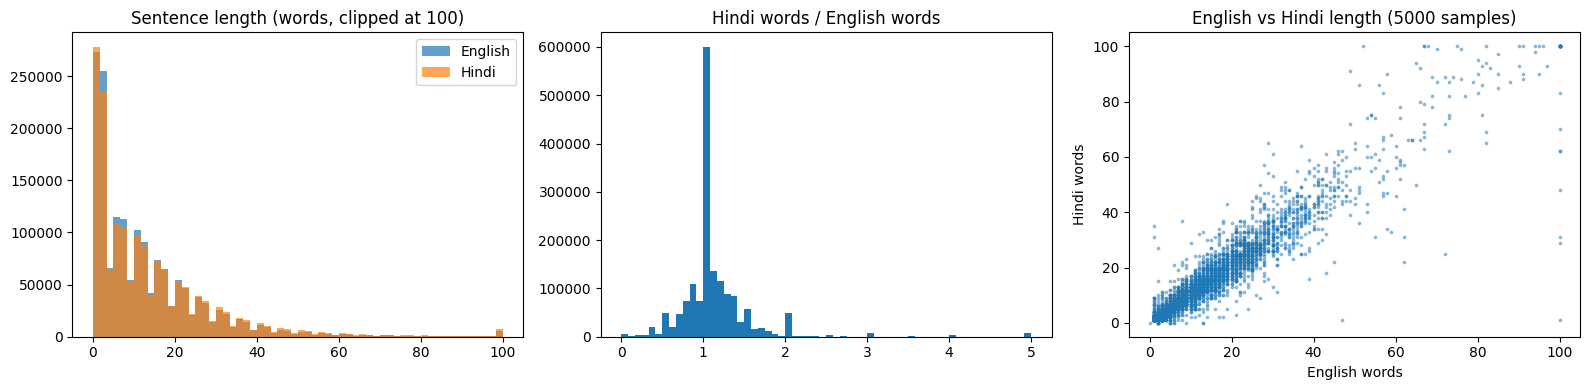

In [13]:
# length plots
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].hist(df["en_words"].clip(upper=100), bins=60, alpha=0.7, label="English")
ax[0].hist(df["hi_words"].clip(upper=100), bins=60, alpha=0.7, label="Hindi")
ax[0].set_title("Sentence length (words, clipped at 100)")
ax[0].legend()

ratio = (df["hi_words"] / df["en_words"].replace(0, np.nan)).clip(upper=5)
ax[1].hist(ratio.dropna(), bins=60)
ax[1].set_title("Hindi words / English words")

ax[2].scatter(df["en_words"].sample(5000, random_state=SEED).clip(upper=100),
              df["hi_words"].sample(5000, random_state=SEED).clip(upper=100), s=3, alpha=0.4)
ax[2].set_title("English vs Hindi length (5000 samples)")
ax[2].set_xlabel("English words"); ax[2].set_ylabel("Hindi words")

plt.tight_layout()
plt.show()

In [14]:
# vocabulary analysis 
from collections import Counter

sample = df.sample(200_000, random_state=SEED)

en_counter = Counter(w.lower() for s in sample["en"].astype(str) for w in s.split())
hi_counter = Counter(w for s in sample["hi"].astype(str) for w in s.split())

print("Unique English words:", f"{len(en_counter):,}")
print("Unique Hindi words  :", f"{len(hi_counter):,}")

for name, c in [("English", en_counter), ("Hindi", hi_counter)]:
    total = sum(c.values())
    rare = sum(1 for w, n in c.items() if n == 1)
    top10k = sum(n for _, n in c.most_common(10_000))
    print(f"\n{name}: words appearing only once = {rare:,} ({rare/len(c)*100:.1f}% of vocab)")
    print(f"{name}: top 10,000 words cover {top10k/total*100:.1f}% of all text")
    print(f"{name}: top 10 words =", c.most_common(10))

Unique English words: 146,032
Unique Hindi words  : 170,389

English: words appearing only once = 80,024 (54.8% of vocab)
English: top 10,000 words cover 86.1% of all text
English: top 10 words = [('the', 157562), ('of', 95956), ('and', 78484), ('to', 62321), ('in', 51110), ('a', 44224), ('is', 36074), ('for', 24704), ('that', 22109), ('-', 21961)]

Hindi: words appearing only once = 102,773 (60.3% of vocab)
Hindi: top 10,000 words cover 86.9% of all text
Hindi: top 10 words = [('के', 102741), ('और', 69555), ('में', 66136), ('की', 57128), ('से', 44756), ('को', 41309), ('है', 39355), ('का', 36434), ('है।', 25729), ('कि', 24042)]


In [18]:
# clean the data
devanagari = re.compile("[\u0900-\u097F]")     # Python's re understands this

def clean_df(df):
    df = df[["en", "hi"]].copy()
    n0 = len(df)

    df["en"] = df["en"].astype(str).str.strip()
    df["hi"] = df["hi"].astype(str).str.strip()
    df = df[(df["en"] != "") & (df["hi"] != "")]
    df = df.drop_duplicates(subset=["en", "hi"])

    # one English sentence -> keep only one Hindi translation
    df = df.drop_duplicates(subset=["en"])

    en_w = df["en"].str.split().str.len()
    hi_w = df["hi"].str.split().str.len()
    df = df[en_w.between(3, 40) & hi_w.between(3, 50)]

    en_w = df["en"].str.split().str.len()
    hi_w = df["hi"].str.split().str.len()
    both = pd.concat([en_w, hi_w], axis=1)
    ratio = both.max(axis=1) / both.min(axis=1)
    df = df[ratio <= 2.5]

    has_hindi = df["hi"].apply(lambda s: devanagari.search(s) is not None)
    df = df[has_hindi]

    print(f"Rows: {n0:,} -> {len(df):,}  (kept {len(df)/n0*100:.1f}%)")
    return df.reset_index(drop=True)

clean = clean_df(df)
print()
print(clean.sample(8, random_state=SEED).to_string())

Rows: 1,662,110 -> 853,656  (kept 51.4%)

                                                                                                                                                                                                                                         en                                                                                                                                                                                                                                                 hi
244174  Enables WebKit 's XSS Auditor (cross - site scripting protection). This feature aims to protect you from certain attacks of malicious websites. It improves your security, but it might not be compatible with all websites. WebKit  के XSS ऑडिटर (क्रॉस-साइट स्क्रिप्टिंग सुरक्षा) को सक्षम करता है. इस विशेषता का उद्देश्य आपको कुछ दुर्भावनापूर्ण वेब साइटों के आक्रमणों से सुरक्षित रखना है. यह आपकी सुरक्षा को बढ़ाता है, लेकिन हो सकता है कि यह सभी वेब साइटों के साथ संगत न हो.


In [21]:
# extra clean
bad_symbols  = re.compile(r"[%<>{}_\\|@#$^*=~\[\]]|https?://|www\.")
latin_letter = re.compile(r"[A-Za-z]")

def latin_ratio(s):
    return len(latin_letter.findall(s)) / max(len(s), 1)

def extra_clean(df):
    n0 = len(df)
    df = df.copy()

    # collapse repeated spaces/newlines
    df["en"] = df["en"].apply(lambda s: re.sub(r"\s+", " ", s).strip())
    df["hi"] = df["hi"].apply(lambda s: re.sub(r"\s+", " ", s).strip())

    # drop software strings, placeholders, urls
    keep = ~df["en"].apply(lambda s: bool(bad_symbols.search(s)))
    keep &= ~df["hi"].apply(lambda s: bool(bad_symbols.search(s)))
    df = df[keep]

    # Hindi side should be mostly Devanagari, not English letters
    df = df[df["hi"].apply(latin_ratio) < 0.10]

    # Hindi sentences should end with the danda "।" (replace a final ".")
    df["hi"] = df["hi"].apply(lambda s: s[:-1] + "।" if s.endswith(".") else s)

    print(f"Rows: {n0:,} -> {len(df):,}  (kept {len(df)/n0*100:.1f}%)")
    return df.reset_index(drop=True)

clean = extra_clean(clean)
print()
print(clean.sample(8, random_state=SEED).to_string())

Rows: 853,656 -> 806,734  (kept 94.5%)

                                                                                                         en                                                                                                     hi
787080  The Department has also computerized the reference media of Library Books in the "Libsys" Software.  विभाग ने ''लिब्सिस'' सॉफ्टवेयर में ग्रंथालय पुस्तैकें के संदर्भ मीडिया का भी कम्यू्टल टरीकरण किया है।
239477                     A few workers actuated with a spirit of service should be obtained from outside.                                                कुछ सेवाभावी कार्यकताओं को बाहर से प्राप्त करना चाहिये।
393789                                                Bill of adventure is not commonly used in the market.                                          जोखिम-पत्रक आम तौर से बाजार में प्रयोग में नहीं लिया जाता है।
44533                         The pressure of the atmosphere holds the paper up and keeps it from dropping.         

In [22]:
# split and save
TRAIN_SIZE = 300_000      # reduce to 100_000 if you have no GPU
VAL_SIZE   = 5_000
TEST_SIZE  = 5_000

clean = clean.sample(frac=1.0, random_state=SEED).reset_index(drop=True)

test_df  = clean.iloc[:TEST_SIZE]
val_df   = clean.iloc[TEST_SIZE:TEST_SIZE + VAL_SIZE]
train_df = clean.iloc[TEST_SIZE + VAL_SIZE : TEST_SIZE + VAL_SIZE + TRAIN_SIZE]

train_df.to_parquet(os.path.join(PROCESSED_DIR, "train.parquet"), index=False)
val_df.to_parquet(os.path.join(PROCESSED_DIR, "val.parquet"), index=False)
test_df.to_parquet(os.path.join(PROCESSED_DIR, "test.parquet"), index=False)

print("train:", f"{len(train_df):,}", "| val:", f"{len(val_df):,}", "| test:", f"{len(test_df):,}")
print("Saved in:", PROCESSED_DIR)

train: 300,000 | val: 5,000 | test: 5,000
Saved in: e:\Pyhton code\Deep Learning\Natural Language Processing (NLP)\translation project\processed_data


In [23]:
# verify the saved files
chk = pd.read_parquet(os.path.join(PROCESSED_DIR, "train.parquet"))
print(chk.shape)
print(chk.head(3).to_string())

(300000, 2)
                                                                   en                                                       hi
0  A Total of 9939 post offices have been computerised by March 2009.  मार्च 2009 तक कुल 9939 डाकघर कम्प्यूटरीकृत हो चुके हैं।
1                                          (ii) RTPS 8th unit 210 MW;                     () आरटीपीएस 8वीं यूनिट, 210 मेगावॉट;
2                                                  Window to Screen 7                                       विंडो से स्क्रीन 7


# phase 2

In [24]:
# load the saved files
import os, re
import numpy as np
import pandas as pd
import sentencepiece as spm

BASE_DIR      = os.getcwd()
PROCESSED_DIR = os.path.join(BASE_DIR, "processed_data")
TOKENIZER_DIR = os.path.join(BASE_DIR, "tokenizer")
os.makedirs(TOKENIZER_DIR, exist_ok=True)

train_df = pd.read_parquet(os.path.join(PROCESSED_DIR, "train.parquet"))
val_df   = pd.read_parquet(os.path.join(PROCESSED_DIR, "val.parquet"))
test_df  = pd.read_parquet(os.path.join(PROCESSED_DIR, "test.parquet"))

print("train:", f"{len(train_df):,}", "| val:", f"{len(val_df):,}", "| test:", f"{len(test_df):,}")
print(train_df.head(3).to_string())

train: 300,000 | val: 5,000 | test: 5,000
                                                                   en                                                       hi
0  A Total of 9939 post offices have been computerised by March 2009.  मार्च 2009 तक कुल 9939 डाकघर कम्प्यूटरीकृत हो चुके हैं।
1                                          (ii) RTPS 8th unit 210 MW;                     () आरटीपीएस 8वीं यूनिट, 210 मेगावॉट;
2                                                  Window to Screen 7                                       विंडो से स्क्रीन 7


In [25]:
# write a text file for tokenizer training
corpus_path = os.path.join(TOKENIZER_DIR, "corpus.txt")

with open(corpus_path, "w", encoding="utf-8") as f:
    for s in train_df["en"]:
        f.write(s.replace("\n", " ") + "\n")
    for s in train_df["hi"]:
        f.write(s.replace("\n", " ") + "\n")

print("Corpus lines:", len(train_df) * 2)
print("Corpus size :", round(os.path.getsize(corpus_path) / 1e6, 1), "MB")

Corpus lines: 600000
Corpus size : 92.1 MB


In [26]:
#train the bpe tokenizer
VOCAB_SIZE = 24_000

spm.SentencePieceTrainer.train(
    input=corpus_path,
    model_prefix=os.path.join(TOKENIZER_DIR, "bpe"),
    vocab_size=VOCAB_SIZE,
    model_type="bpe",
    character_coverage=0.9995,
    pad_id=0, unk_id=1, bos_id=2, eos_id=3,
    pad_piece="<pad>", unk_piece="<unk>", bos_piece="<bos>", eos_piece="<eos>",
    input_sentence_size=1_000_000,
    shuffle_input_sentence=True,
    num_threads=os.cpu_count(),
)

print("Saved:", os.listdir(TOKENIZER_DIR))

Saved: ['bpe.model', 'bpe.vocab', 'corpus.txt']


In [27]:
#load and test
sp = spm.SentencePieceProcessor(model_file=os.path.join(TOKENIZER_DIR, "bpe.model"))

print("Vocab size:", sp.get_piece_size())
print("Special ids -> pad:", sp.pad_id(), "| unk:", sp.unk_id(), "| bos:", sp.bos_id(), "| eos:", sp.eos_id())
print()

tests = [
    "How are you?",
    "India is a very big country.",
    "The government announced a new education policy yesterday.",
    "आप कैसे हैं?",
    "भारत एक बहुत बड़ा देश है।",
]
for t in tests:
    ids = sp.encode(t)
    print("Text  :", t)
    print("Pieces:", sp.encode(t, out_type=str))
    print("IDs   :", ids)
    print("Decode:", sp.decode(ids))
    print()

Vocab size: 24000
Special ids -> pad: 0 | unk: 1 | bos: 2 | eos: 3

Text  : How are you?
Pieces: ['▁How', '▁are', '▁you', '?']
IDs   : [2108, 201, 194, 23969]
Decode: How are you?

Text  : India is a very big country.
Pieces: ['▁India', '▁is', '▁a', '▁very', '▁big', '▁country', '.']
IDs   : [421, 96, 7, 1107, 3342, 1037, 23901]
Decode: India is a very big country.

Text  : The government announced a new education policy yesterday.
Pieces: ['▁The', '▁government', '▁announced', '▁a', '▁new', '▁education', '▁policy', '▁yesterday', '.']
IDs   : [122, 1929, 9583, 7, 818, 2130, 3020, 13595, 23901]
Decode: The government announced a new education policy yesterday.

Text  : आप कैसे हैं?
Pieces: ['▁आप', '▁कैसे', '▁हैं', '?']
IDs   : [369, 2734, 133, 23969]
Decode: आप कैसे हैं?

Text  : भारत एक बहुत बड़ा देश है।
Pieces: ['▁भारत', '▁एक', '▁बहुत', '▁बड़ा', '▁देश', '▁है', '।']
IDs   : [425, 126, 662, 1791, 660, 23, 23908]
Decode: भारत एक बहुत बड़ा देश है।



In [28]:
# token length analysis
sample = train_df.sample(30_000, random_state=42)

en_len = [len(x) for x in sp.encode(sample["en"].tolist())]
hi_len = [len(x) for x in sp.encode(sample["hi"].tolist())]

stats = pd.DataFrame({"en_tokens": en_len, "hi_tokens": hi_len})
print(stats.describe(percentiles=[.5, .9, .95, .99]).round(1))

en_words = sample["en"].str.split().str.len().sum()
hi_words = sample["hi"].str.split().str.len().sum()
print("\nTokens per word -> English:", round(sum(en_len) / en_words, 2),
      "| Hindi:", round(sum(hi_len) / hi_words, 2))

       en_tokens  hi_tokens
count    30000.0    30000.0
mean        20.0       20.9
std         11.8       12.5
min          3.0        3.0
50%         17.0       18.0
90%         37.0       39.0
95%         43.0       45.0
99%         52.0       57.0
max         94.0      102.0

Tokens per word -> English: 1.32 | Hindi: 1.3


In [29]:
# unknown token check on validation data
def unk_rate(texts):
    ids = sp.encode(texts)
    total = sum(len(x) for x in ids)
    unk = sum(x.count(sp.unk_id()) for x in ids)
    return unk, total

for lang in ["en", "hi"]:
    unk, total = unk_rate(val_df[lang].tolist())
    print(f"{lang}: unk tokens = {unk:,} out of {total:,} ({unk / total * 100:.4f}%)")

en: unk tokens = 147 out of 98,336 (0.1495%)
hi: unk tokens = 182 out of 103,265 (0.1762%)


In [30]:
#set max len, filter, encode and save
MAX_LEN = 64     

def encode_split(df, name):
    en_ids = sp.encode(df["en"].tolist())
    hi_ids = sp.encode(df["hi"].tolist())

    out = pd.DataFrame({"en_ids": en_ids, "hi_ids": hi_ids})
    keep = (out["en_ids"].str.len() <= MAX_LEN - 2) & (out["hi_ids"].str.len() <= MAX_LEN - 2)
    kept = out[keep].reset_index(drop=True)

    print(f"{name:5s}: {len(out):,} -> {len(kept):,}  (kept {len(kept) / len(out) * 100:.1f}%)")
    kept.to_parquet(os.path.join(PROCESSED_DIR, f"{name}_tok.parquet"), index=False)
    return kept

train_tok = encode_split(train_df, "train")
val_tok   = encode_split(val_df,   "val")
test_tok  = encode_split(test_df,  "test")

train: 300,000 -> 298,488  (kept 99.5%)
val  : 5,000 -> 4,977  (kept 99.5%)
test : 5,000 -> 4,978  (kept 99.6%)


In [31]:
# verify one example round trip
chk = pd.read_parquet(os.path.join(PROCESSED_DIR, "train_tok.parquet"))
row = chk.iloc[0]

print("English ids :", list(row["en_ids"]))
print("English text:", sp.decode(list(row["en_ids"])))
print()
print("Hindi ids   :", list(row["hi_ids"]))
print("Hindi text  :", sp.decode(list(row["hi_ids"])))

English ids : [np.int64(102), np.int64(19233), np.int64(32), np.int64(19741), np.int64(23967), np.int64(23959), np.int64(3164), np.int64(10689), np.int64(286), np.int64(522), np.int64(3779), np.int64(1293), np.int64(256), np.int64(5883), np.int64(932), np.int64(5579)]
English text: A Total of 9939 post offices have been computerised by March 2009.

Hindi ids   : [np.int64(5345), np.int64(9801), np.int64(463), np.int64(3026), np.int64(19741), np.int64(23967), np.int64(23959), np.int64(5800), np.int64(10804), np.int64(4030), np.int64(8247), np.int64(223), np.int64(1463), np.int64(104), np.int64(3379), np.int64(133), np.int64(23908)]
Hindi text  : मार्च 2009 तक कुल 9939 डाकघर कम्प्यूटरीकृत हो चुके हैं।


# phase 3

In [32]:
# import, constants load tokenized data
import os, json, random
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader, Sampler
from torch.nn.utils.rnn import pad_sequence
import sentencepiece as spm

BASE_DIR      = os.getcwd()
PROCESSED_DIR = os.path.join(BASE_DIR, "processed_data")
TOKENIZER_DIR = os.path.join(BASE_DIR, "tokenizer")

sp = spm.SentencePieceProcessor(model_file=os.path.join(TOKENIZER_DIR, "bpe.model"))

PAD, UNK, BOS, EOS = sp.pad_id(), sp.unk_id(), sp.bos_id(), sp.eos_id()
VOCAB_SIZE = sp.get_piece_size()
MAX_LEN = 64
print("PAD, UNK, BOS, EOS =", PAD, UNK, BOS, EOS, "| vocab:", VOCAB_SIZE)

def load_split(name):
    df = pd.read_parquet(os.path.join(PROCESSED_DIR, f"{name}_tok.parquet"))
    en = df["en_ids"].apply(lambda x: x.tolist()).tolist()
    hi = df["hi_ids"].apply(lambda x: x.tolist()).tolist()
    return en, hi

train_en, train_hi = load_split("train")
val_en,   val_hi   = load_split("val")
test_en,  test_hi  = load_split("test")

print("train:", len(train_en), "| val:", len(val_en), "| test:", len(test_en))

PAD, UNK, BOS, EOS = 0 1 2 3 | vocab: 24000
train: 298488 | val: 4977 | test: 4978


In [33]:
#dataset class
class TranslationDataset(Dataset):
    def __init__(self, en_ids, hi_ids):
        self.en = en_ids
        self.hi = hi_ids

    def __len__(self):
        return len(self.en)

    def __getitem__(self, i):
        src = [BOS] + self.en[i] + [EOS]
        tgt = [BOS] + self.hi[i] + [EOS]
        return torch.tensor(src, dtype=torch.long), torch.tensor(tgt, dtype=torch.long)

train_ds = TranslationDataset(train_en, train_hi)
val_ds   = TranslationDataset(val_en,   val_hi)
test_ds  = TranslationDataset(test_en,  test_hi)

src0, tgt0 = train_ds[0]
print("src:", src0.tolist())
print("tgt:", tgt0.tolist())

src: [2, 102, 19233, 32, 19741, 23967, 23959, 3164, 10689, 286, 522, 3779, 1293, 256, 5883, 932, 5579, 3]
tgt: [2, 5345, 9801, 463, 3026, 19741, 23967, 23959, 5800, 10804, 4030, 8247, 223, 1463, 104, 3379, 133, 23908, 3]


In [ ]:
# collate function (padding and teacher-forcing shift)
def collate_fn(batch):
    srcs, tgts = zip(*batch)
    src     = pad_sequence(srcs, batch_first=True, padding_value=PAD)   # (B, S)
    tgt_pad = pad_sequence(tgts, batch_first=True, padding_value=PAD)   # (B, T+1)

    tgt_in  = tgt_pad[:, :-1]    # <bos> w1 w2 ... wn         (decoder input)
    tgt_out = tgt_pad[:, 1:]     # w1 w2 ... wn <eos>         (decoder target)
    return src, tgt_in, tgt_out

In [35]:
# bucket sampler and dataloaders
class BucketBatchSampler(Sampler):
    """Groups sentences of similar length into the same batch to reduce padding."""
    def __init__(self, lengths, batch_size, shuffle=True, chunk_mult=50):
        self.lengths = np.array(lengths)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.chunk = batch_size * chunk_mult

    def __iter__(self):
        idx = np.random.permutation(len(self.lengths)) if self.shuffle else np.arange(len(self.lengths))
        batches = []
        for start in range(0, len(idx), self.chunk):
            chunk_idx = idx[start:start + self.chunk]
            chunk_idx = chunk_idx[np.argsort(self.lengths[chunk_idx])]     # sort inside chunk
            for b in range(0, len(chunk_idx), self.batch_size):
                batches.append(chunk_idx[b:b + self.batch_size].tolist())
        if self.shuffle:
            random.shuffle(batches)                                         # shuffle batch order
        return iter(batches)

    def __len__(self):
        return (len(self.lengths) + self.batch_size - 1) // self.batch_size

def get_lengths(en, hi):
    return [max(len(e), len(h)) + 2 for e, h in zip(en, hi)]

BATCH_SIZE = 64

train_loader = DataLoader(train_ds, batch_sampler=BucketBatchSampler(get_lengths(train_en, train_hi), BATCH_SIZE, shuffle=True),
                          collate_fn=collate_fn, num_workers=0)
val_loader   = DataLoader(val_ds,   batch_sampler=BucketBatchSampler(get_lengths(val_en, val_hi), BATCH_SIZE, shuffle=False),
                          collate_fn=collate_fn, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_sampler=BucketBatchSampler(get_lengths(test_en, test_hi), BATCH_SIZE, shuffle=False),
                          collate_fn=collate_fn, num_workers=0)

print("batches per epoch -> train:", len(train_loader), "| val:", len(val_loader), "| test:", len(test_loader))

batches per epoch -> train: 4664 | val: 78 | test: 78


In [36]:
#look inside one batch
src, tgt_in, tgt_out = next(iter(train_loader))

print("src     :", tuple(src.shape))
print("tgt_in  :", tuple(tgt_in.shape))
print("tgt_out :", tuple(tgt_out.shape))
print()

i = 0
print("English input   :", sp.decode([t for t in src[i].tolist() if t > 3]))
print("Hindi decoder in:", tgt_in[i].tolist())
print("Hindi target    :", tgt_out[i].tolist())
print("Hindi text      :", sp.decode([t for t in tgt_out[i].tolist() if t > 3]))

src     : (64, 44)
tgt_in  : (64, 43)
tgt_out : (64, 43)

English input   : Speaking on the occasion the President said our universities and academic institutions must take a lead in imparting education which would help us meet the moral challenge of our times.
Hindi decoder in: [2, 129, 1525, 103, 10196, 613, 748, 209, 533, 77, 865, 2869, 331, 20602, 4255, 78, 1346, 1054, 254, 52, 8904, 2935, 183, 23912, 602, 798, 23898, 2674, 1248, 366, 647, 67, 6793, 9285, 83, 5322, 254, 52, 1521, 8204, 23908, 3, 0]
Hindi target    : [129, 1525, 103, 10196, 613, 748, 209, 533, 77, 865, 2869, 331, 20602, 4255, 78, 1346, 1054, 254, 52, 8904, 2935, 183, 23912, 602, 798, 23898, 2674, 1248, 366, 647, 67, 6793, 9285, 83, 5322, 254, 52, 1521, 8204, 23908, 3, 0, 0]
Hindi text      : इस अवसर पर बोलते हुए राष्ट्रपति ने कहा कि हमारे विश्वविद्यालय तथा अकादमिक संस्थानों को शिक्षा प्रदान करने में अग्रणी भूमिका निभानी चाहिए, जिससे हमें अपने समय की नैतिक चुनौतियों का सामना करने में सहायता मिलेगी।


In [37]:
#masks
def make_src_mask(src):
    # (B, 1, 1, S): hide <pad> keys in encoder self-attention and decoder cross-attention
    return (src != PAD).unsqueeze(1).unsqueeze(2)

def make_tgt_mask(tgt_in):
    # (B, 1, T, T): hide <pad> AND hide future positions
    T = tgt_in.size(1)
    pad_mask    = (tgt_in != PAD).unsqueeze(1).unsqueeze(2)                              # (B,1,1,T)
    causal_mask = torch.tril(torch.ones(T, T, dtype=torch.bool, device=tgt_in.device))   # (T,T)
    return pad_mask & causal_mask

# --- tiny demo: 5 positions, last 2 are padding ---
demo = torch.tensor([[BOS, 10, 11, PAD, PAD]])
print("Target mask for [BOS, 10, 11, PAD, PAD]  (1 = can look, 0 = blocked)")
print(make_tgt_mask(demo)[0, 0].int())

# --- real batch shapes ---
print("\nsrc_mask:", tuple(make_src_mask(src).shape))
print("tgt_mask:", tuple(make_tgt_mask(tgt_in).shape))

Target mask for [BOS, 10, 11, PAD, PAD]  (1 = can look, 0 = blocked)
tensor([[1, 0, 0, 0, 0],
        [1, 1, 0, 0, 0],
        [1, 1, 1, 0, 0],
        [1, 1, 1, 0, 0],
        [1, 1, 1, 0, 0]], dtype=torch.int32)

src_mask: (64, 1, 1, 44)
tgt_mask: (64, 1, 43, 43)


In [38]:
#why bucketing helps
def padding_waste(loader, n_batches=200):
    real, total = 0, 0
    for k, (s, ti, to) in enumerate(loader):
        if k >= n_batches:
            break
        real  += (s != PAD).sum().item()
        total += s.numel()
    return 100 * (1 - real / total)

random_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)

print(f"Padding in source batches, random batching : {padding_waste(random_loader):.1f}%")
print(f"Padding in source batches, bucket batching : {padding_waste(train_loader):.1f}%")

Padding in source batches, random batching : 59.3%
Padding in source batches, bucket batching : 11.4%


In [39]:
#save the settings for later phases
config = {
    "vocab_size": VOCAB_SIZE, "pad_id": PAD, "unk_id": UNK, "bos_id": BOS, "eos_id": EOS,
    "max_len": MAX_LEN, "batch_size": BATCH_SIZE,
}
with open(os.path.join(BASE_DIR, "config.json"), "w") as f:
    json.dump(config, f, indent=2)
print(config)

{'vocab_size': 24000, 'pad_id': 0, 'unk_id': 1, 'bos_id': 2, 'eos_id': 3, 'max_len': 64, 'batch_size': 64}


# phase 4
# Blueprint
English ids -> Embedding*sqrt(d) + PosEnc -> [Encoder layer x4] -> memory
                                                                     |
Hindi ids   -> Embedding*sqrt(d) + PosEnc -> [Decoder layer x4] <----+  (cross-attention)
                                                      |
                                           Linear (d_model -> 24000) -> logits

Encoder layer: x -> LN -> SelfAttn -> +x -> LN -> FeedForward -> +x
Decoder layer: x -> LN -> MaskedSelfAttn -> +x -> LN -> CrossAttn(memory) -> +x -> LN -> FFN -> +x

In [40]:
#imports, positional encoding masks
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))      # (1, max_len, d_model)

    def forward(self, x):                                # x: (B, L, d_model)
        x = x + self.pe[:, : x.size(1)]
        return self.dropout(x)


def make_src_mask(src, pad_id):
    # (B, 1, 1, S): True where the token is real (not pad)
    return (src != pad_id).unsqueeze(1).unsqueeze(2)


def make_tgt_mask(tgt_in, pad_id):
    # (B, 1, T, T): real tokens only AND no peeking at future positions
    T = tgt_in.size(1)
    pad_mask = (tgt_in != pad_id).unsqueeze(1).unsqueeze(2)
    causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=tgt_in.device))
    return pad_mask & causal

In [41]:
#multi-head attention

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.h = n_heads
        self.d_k = d_model // n_heads
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)
        self.save_attn = False          # set True later to visualize attention
        self.attn_weights = None

    def forward(self, q, k, v, mask=None):
        B = q.size(0)

        def split(x, layer):            # (B, L, d_model) -> (B, h, L, d_k)
            return layer(x).view(B, -1, self.h, self.d_k).transpose(1, 2)

        Q, K, V = split(q, self.w_q), split(k, self.w_k), split(v, self.w_v)

        scores = Q @ K.transpose(-2, -1) / math.sqrt(self.d_k)     # (B, h, Lq, Lk)
        if mask is not None:
            scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)

        attn = F.softmax(scores, dim=-1)
        if self.save_attn:
            self.attn_weights = attn.detach()
        attn = self.dropout(attn)

        out = attn @ V                                              # (B, h, Lq, d_k)
        out = out.transpose(1, 2).contiguous().view(B, -1, self.h * self.d_k)
        return self.w_o(out)

Self-attention : Q, K, V all come from the same sentence
Cross-attention: Q comes from the decoder, K and V come from the encoder output
Shapes         : (B, L, 256) -> (B, 8, L, 32) -> scores (B, 8, Lq, Lk) -> (B, L, 256)

In [42]:
#feed forward and encoder

class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.fc1 = nn.Linear(d_model, d_ff)
        self.fc2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.fc2(self.dropout(F.relu(self.fc1(x))))


class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, src_mask):
        h = self.norm1(x)
        x = x + self.drop(self.self_attn(h, h, h, src_mask))
        h = self.norm2(x)
        x = x + self.drop(self.ff(h))
        return x


class Encoder(nn.Module):
    def __init__(self, n_layers, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.layers = nn.ModuleList(
            [EncoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)]
        )
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x, src_mask):
        for layer in self.layers:
            x = layer(x, src_mask)
        return self.norm(x)

In [43]:
#decoder

class DecoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.cross_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, memory, src_mask, tgt_mask):
        h = self.norm1(x)
        x = x + self.drop(self.self_attn(h, h, h, tgt_mask))
        h = self.norm2(x)
        x = x + self.drop(self.cross_attn(h, memory, memory, src_mask))
        h = self.norm3(x)
        x = x + self.drop(self.ff(h))
        return x


class Decoder(nn.Module):
    def __init__(self, n_layers, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.layers = nn.ModuleList(
            [DecoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)]
        )
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x, memory, src_mask, tgt_mask):
        for layer in self.layers:
            x = layer(x, memory, src_mask, tgt_mask)
        return self.norm(x)

In [44]:
#the full transformer

class Transformer(nn.Module):
    def __init__(self, vocab_size, d_model=256, n_heads=8, n_layers=4,
                 d_ff=1024, dropout=0.1, max_len=128, pad_id=0):
        super().__init__()
        self.d_model = d_model
        self.pad_id = pad_id

        self.embed = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.pos = PositionalEncoding(d_model, max_len, dropout)
        self.encoder = Encoder(n_layers, d_model, n_heads, d_ff, dropout)
        self.decoder = Decoder(n_layers, d_model, n_heads, d_ff, dropout)

        self.out_proj = nn.Linear(d_model, vocab_size, bias=False)
        self.out_proj.weight = self.embed.weight          # weight tying
        self._init_weights()

    def _init_weights(self):
        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)
        nn.init.normal_(self.embed.weight, mean=0.0, std=self.d_model ** -0.5)
        with torch.no_grad():
            self.embed.weight[self.pad_id].fill_(0.0)

    def encode(self, src, src_mask):
        x = self.pos(self.embed(src) * math.sqrt(self.d_model))
        return self.encoder(x, src_mask)

    def decode(self, tgt_in, memory, src_mask, tgt_mask):
        x = self.pos(self.embed(tgt_in) * math.sqrt(self.d_model))
        x = self.decoder(x, memory, src_mask, tgt_mask)
        return self.out_proj(x)                           # (B, T, vocab)

    def forward(self, src, tgt_in):
        src_mask = make_src_mask(src, self.pad_id)
        tgt_mask = make_tgt_mask(tgt_in, self.pad_id)
        memory = self.encode(src, src_mask)
        return self.decode(tgt_in, memory, src_mask, tgt_mask)

In [46]:
# %%
import os, sys

print("Current folder :", os.getcwd())
print("model.py here  :", os.path.exists("model.py"))
print("Python files   :", [f for f in os.listdir(".") if f.endswith(".py")])

# search for model.py in this folder and all subfolders
for root, _, files in os.walk(os.getcwd()):
    if "model.py" in files:
        print("Found at       :", os.path.join(root, "model.py"))

Current folder : e:\Pyhton code\Deep Learning\Natural Language Processing (NLP)\translation project
model.py here  : False
Python files   : []


In [47]:
# %%
code = r'''
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))      # (1, max_len, d_model)

    def forward(self, x):                                # x: (B, L, d_model)
        x = x + self.pe[:, : x.size(1)]
        return self.dropout(x)


def make_src_mask(src, pad_id):
    # (B, 1, 1, S): True where the token is real (not pad)
    return (src != pad_id).unsqueeze(1).unsqueeze(2)


def make_tgt_mask(tgt_in, pad_id):
    # (B, 1, T, T): real tokens only AND no peeking at future positions
    T = tgt_in.size(1)
    pad_mask = (tgt_in != pad_id).unsqueeze(1).unsqueeze(2)
    causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=tgt_in.device))
    return pad_mask & causal


class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.h = n_heads
        self.d_k = d_model // n_heads
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)
        self.save_attn = False          # set True later to visualize attention
        self.attn_weights = None

    def forward(self, q, k, v, mask=None):
        B = q.size(0)

        def split(x, layer):            # (B, L, d_model) -> (B, h, L, d_k)
            return layer(x).view(B, -1, self.h, self.d_k).transpose(1, 2)

        Q, K, V = split(q, self.w_q), split(k, self.w_k), split(v, self.w_v)

        scores = Q @ K.transpose(-2, -1) / math.sqrt(self.d_k)     # (B, h, Lq, Lk)
        if mask is not None:
            scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)

        attn = F.softmax(scores, dim=-1)
        if self.save_attn:
            self.attn_weights = attn.detach()
        attn = self.dropout(attn)

        out = attn @ V                                              # (B, h, Lq, d_k)
        out = out.transpose(1, 2).contiguous().view(B, -1, self.h * self.d_k)
        return self.w_o(out)


class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.fc1 = nn.Linear(d_model, d_ff)
        self.fc2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.fc2(self.dropout(F.relu(self.fc1(x))))


class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, src_mask):
        h = self.norm1(x)
        x = x + self.drop(self.self_attn(h, h, h, src_mask))
        h = self.norm2(x)
        x = x + self.drop(self.ff(h))
        return x


class Encoder(nn.Module):
    def __init__(self, n_layers, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.layers = nn.ModuleList(
            [EncoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)]
        )
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x, src_mask):
        for layer in self.layers:
            x = layer(x, src_mask)
        return self.norm(x)


class DecoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.cross_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, memory, src_mask, tgt_mask):
        h = self.norm1(x)
        x = x + self.drop(self.self_attn(h, h, h, tgt_mask))
        h = self.norm2(x)
        x = x + self.drop(self.cross_attn(h, memory, memory, src_mask))
        h = self.norm3(x)
        x = x + self.drop(self.ff(h))
        return x


class Decoder(nn.Module):
    def __init__(self, n_layers, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.layers = nn.ModuleList(
            [DecoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)]
        )
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x, memory, src_mask, tgt_mask):
        for layer in self.layers:
            x = layer(x, memory, src_mask, tgt_mask)
        return self.norm(x)


class Transformer(nn.Module):
    def __init__(self, vocab_size, d_model=256, n_heads=8, n_layers=4,
                 d_ff=1024, dropout=0.1, max_len=128, pad_id=0):
        super().__init__()
        self.d_model = d_model
        self.pad_id = pad_id

        self.embed = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.pos = PositionalEncoding(d_model, max_len, dropout)
        self.encoder = Encoder(n_layers, d_model, n_heads, d_ff, dropout)
        self.decoder = Decoder(n_layers, d_model, n_heads, d_ff, dropout)

        self.out_proj = nn.Linear(d_model, vocab_size, bias=False)
        self.out_proj.weight = self.embed.weight          # weight tying
        self._init_weights()

    def _init_weights(self):
        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)
        nn.init.normal_(self.embed.weight, mean=0.0, std=self.d_model ** -0.5)
        with torch.no_grad():
            self.embed.weight[self.pad_id].fill_(0.0)

    def encode(self, src, src_mask):
        x = self.pos(self.embed(src) * math.sqrt(self.d_model))
        return self.encoder(x, src_mask)

    def decode(self, tgt_in, memory, src_mask, tgt_mask):
        x = self.pos(self.embed(tgt_in) * math.sqrt(self.d_model))
        x = self.decoder(x, memory, src_mask, tgt_mask)
        return self.out_proj(x)                           # (B, T, vocab)

    def forward(self, src, tgt_in):
        src_mask = make_src_mask(src, self.pad_id)
        tgt_mask = make_tgt_mask(tgt_in, self.pad_id)
        memory = self.encode(src, src_mask)
        return self.decode(tgt_in, memory, src_mask, tgt_mask)
'''

import os
with open("model.py", "w", encoding="utf-8") as f:
    f.write(code.lstrip())

print("Written to:", os.path.abspath("model.py"))
print("Classes   :", [l.split("(")[0].replace("class ", "") for l in code.splitlines() if l.startswith("class ")])

Written to: e:\Pyhton code\Deep Learning\Natural Language Processing (NLP)\translation project\model.py
Classes   : ['PositionalEncoding', 'MultiHeadAttention', 'FeedForward', 'EncoderLayer', 'Encoder', 'DecoderLayer', 'Decoder', 'Transformer']


In [48]:
#create the model and count parameters
import importlib, model
importlib.reload(model)
from model import Transformer, make_src_mask, make_tgt_mask

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

net = Transformer(
    vocab_size=VOCAB_SIZE, d_model=256, n_heads=8, n_layers=4,
    d_ff=1024, dropout=0.1, max_len=128, pad_id=PAD,
).to(device)

total = sum(p.numel() for p in net.parameters())
print(f"Total parameters : {total:,}  ({total / 1e6:.1f}M)")
print(f"Embedding table  : {net.embed.weight.numel():,}")
print(f"Encoder          : {sum(p.numel() for p in net.encoder.parameters()):,}")
print(f"Decoder          : {sum(p.numel() for p in net.decoder.parameters()):,}")
print("Device           :", device)

Total parameters : 13,517,824  (13.5M)
Embedding table  : 6,144,000
Encoder          : 3,159,552
Decoder          : 4,214,272
Device           : cuda


In [49]:
# forward pass, initial loss, gpu memory
import math
criterion = torch.nn.CrossEntropyLoss(ignore_index=PAD)

src, tgt_in, tgt_out = [t.to(device) for t in next(iter(train_loader))]

net.train()
logits = net(src, tgt_in)
loss = criterion(logits.reshape(-1, VOCAB_SIZE), tgt_out.reshape(-1))
loss.backward()

print("src    :", tuple(src.shape))
print("tgt_in :", tuple(tgt_in.shape))
print("logits :", tuple(logits.shape), " (batch, target length, vocab)")
print(f"\nInitial loss          : {loss.item():.3f}")
print(f"Random-guess loss     : ln({VOCAB_SIZE}) = {math.log(VOCAB_SIZE):.3f}")

if device.type == "cuda":
    print(f"Peak GPU memory (1 batch, fwd+bwd): {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")

src    : (64, 19)
tgt_in : (64, 18)
logits : (64, 18, 24000)  (batch, target length, vocab)

Initial loss          : 10.656
Random-guess loss     : ln(24000) = 10.086
Peak GPU memory (1 batch, fwd+bwd): 0.74 GB


In [50]:
# correctness test(masking)
net.eval()
with torch.no_grad():
    s, ti = src[:4], tgt_in[:4]

    # Test 1: changing the LAST decoder input token must not change earlier outputs
    base = net(s, ti)
    ti2 = ti.clone()
    ti2[:, -1] = 100
    changed = net(s, ti2)
    ok1 = torch.allclose(base[:, :-1], changed[:, :-1], atol=1e-4)
    print("Causal mask test (no peeking at the future):", "PASS" if ok1 else "FAIL")

    # Test 2: adding extra PAD columns to the source must not change the encoder output
    S = s.size(1)
    s_pad = torch.cat([s, torch.full((4, 7), PAD, device=device)], dim=1)
    m1 = net.encode(s,     make_src_mask(s,     PAD))
    m2 = net.encode(s_pad, make_src_mask(s_pad, PAD))
    ok2 = torch.allclose(m1, m2[:, :S], atol=1e-4)
    print("Padding mask test (pads are ignored)        :", "PASS" if ok2 else "FAIL")

Causal mask test (no peeking at the future): PASS
Padding mask test (pads are ignored)        : PASS


# phase 5

In [51]:
# settings and imports
import os, time, json, math
import torch, torch.nn as nn, torch.nn.functional as F
from tqdm.auto import tqdm

import sys
sys.path.insert(0, os.getcwd())
from model import Transformer, make_src_mask, make_tgt_mask

CKPT_DIR = os.path.join(BASE_DIR, "checkpoints")
os.makedirs(CKPT_DIR, exist_ok=True)

# model settings
D_MODEL, N_HEADS, N_LAYERS, D_FF, DROPOUT = 256, 8, 4, 1024, 0.1

# training settings
WARMUP_STEPS    = 4000
LR_FACTOR       = 0.7
LABEL_SMOOTHING = 0.1
GRAD_CLIP       = 1.0

device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("Device:", device, "| mixed precision:", use_amp)

Device: cuda | mixed precision: True


In [57]:
# build model, optimizer, scheduler, loss
net = Transformer(vocab_size=VOCAB_SIZE, d_model=D_MODEL, n_heads=N_HEADS, n_layers=N_LAYERS,
                  d_ff=D_FF, dropout=DROPOUT, max_len=128, pad_id=PAD).to(device)

criterion = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=LABEL_SMOOTHING)

optimizer = torch.optim.Adam(net.parameters(), lr=1.0, betas=(0.9, 0.98), eps=1e-9)

def noam(step):
    s = step + 1
    return LR_FACTOR * D_MODEL ** -0.5 * min(s ** -0.5, s * WARMUP_STEPS ** -1.5)

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, noam)
scaler    = torch.amp.GradScaler("cuda", enabled=use_amp)

history     = {"train_loss": [], "val_loss": [], "val_ppl": [], "lr": []}
best_val    = float("inf")
start_epoch = 0

print(f"Parameters : {sum(p.numel() for p in net.parameters()):,}")
print(f"LR at step 1      : {noam(0):.2e}")
print(f"Peak LR (step {WARMUP_STEPS}): {noam(WARMUP_STEPS - 1):.2e}")
print(f"Batches per epoch : {len(train_loader)}")

Parameters : 13,517,824
LR at step 1      : 1.73e-07
Peak LR (step 4000): 6.92e-04
Batches per epoch : 4664


In [53]:
# worst-case gpu memory test
if device.type == "cuda":
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    B = BATCH_SIZE
    s  = torch.randint(4, VOCAB_SIZE, (B, MAX_LEN),     device=device)
    ti = torch.randint(4, VOCAB_SIZE, (B, MAX_LEN - 1), device=device)
    to = torch.randint(4, VOCAB_SIZE, (B, MAX_LEN - 1), device=device)

    net.train()
    with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
        logits = net(s, ti)
        loss = criterion(logits.reshape(-1, VOCAB_SIZE), to.reshape(-1))
    scaler.scale(loss).backward()

    print(f"Worst-case peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")
    print(f"GPU total memory          : {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

    net.zero_grad(set_to_none=True)
    del logits, loss, s, ti, to
    torch.cuda.empty_cache()

Worst-case peak GPU memory: 2.13 GB
GPU total memory          : 4.29 GB


In [54]:
#helper functions
@torch.no_grad()
def evaluate(loader):
    net.eval()
    tot_loss, tot_tok = 0.0, 0
    for src, tgt_in, tgt_out in loader:
        src, tgt_in, tgt_out = src.to(device), tgt_in.to(device), tgt_out.to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            logits = net(src, tgt_in)
        loss = F.cross_entropy(logits.float().reshape(-1, VOCAB_SIZE), tgt_out.reshape(-1),
                               ignore_index=PAD, reduction="sum")
        tot_loss += loss.item()
        tot_tok  += (tgt_out != PAD).sum().item()
    avg = tot_loss / tot_tok
    return avg, math.exp(avg)


@torch.no_grad()
def greedy_translate(text, max_new=64):
    net.eval()
    ids = [BOS] + sp.encode(text)[: MAX_LEN - 2] + [EOS]
    src = torch.tensor([ids], device=device)
    src_mask = make_src_mask(src, PAD)
    memory = net.encode(src, src_mask)                    # encode English once

    out = [BOS]
    for _ in range(max_new):
        tgt = torch.tensor([out], device=device)
        tgt_mask = make_tgt_mask(tgt, PAD)
        logits = net.decode(tgt, memory, src_mask, tgt_mask)
        nxt = logits[0, -1].argmax().item()               # most likely next token
        if nxt == EOS:
            break
        out.append(nxt)
    return sp.decode(out[1:])


sample_idx = [i for i in range(len(val_en)) if 6 <= len(val_en[i]) <= 15][:5]

def show_samples():
    for i in sample_idx:
        print("  EN :", sp.decode(val_en[i]))
        print("  REF:", sp.decode(val_hi[i]))
        print("  OUT:", greedy_translate(sp.decode(val_en[i])))
        print()


def save_checkpoint(path, epochs_done):
    torch.save({
        "epochs_done": epochs_done,
        "model": net.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "scaler": scaler.state_dict(),
        "best_val": best_val,
        "history": history,
        "model_cfg": dict(vocab_size=VOCAB_SIZE, d_model=D_MODEL, n_heads=N_HEADS,
                          n_layers=N_LAYERS, d_ff=D_FF, dropout=DROPOUT, max_len=128, pad_id=PAD),
    }, path)

print("Helpers ready. Samples use val indices:", sample_idx)

Helpers ready. Samples use val indices: [3, 4, 5, 6, 7]


In [55]:
# the training function
def train_model(num_epochs, max_steps=None):
    global best_val, start_epoch

    for epoch in range(start_epoch, start_epoch + num_epochs):
        t0 = time.time()
        net.train()
        run_loss, n_batches = torch.zeros((), device=device), 0

        pbar = tqdm(train_loader, desc=f"Epoch {epoch + 1}", leave=False)
        for step, (src, tgt_in, tgt_out) in enumerate(pbar):
            if max_steps is not None and step >= max_steps:
                break
            src, tgt_in, tgt_out = src.to(device), tgt_in.to(device), tgt_out.to(device)

            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                logits = net(src, tgt_in)
                loss = criterion(logits.reshape(-1, VOCAB_SIZE), tgt_out.reshape(-1))

            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(net.parameters(), GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            run_loss += loss.detach()
            n_batches += 1
            if step % 50 == 0:
                pbar.set_postfix(loss=f"{(run_loss / n_batches).item():.3f}",
                                 lr=f"{scheduler.get_last_lr()[0]:.2e}")

        train_loss = (run_loss / n_batches).item()
        elapsed = time.time() - t0

        if max_steps is not None:      # quick test: stop here and print the time estimate
            est = elapsed / n_batches * len(train_loader) / 60
            print(f"{n_batches} steps in {elapsed:.0f}s -> {n_batches / elapsed:.1f} steps/s")
            print(f"Estimated time for one full epoch: {est:.1f} minutes")
            print(f"Train loss after test: {train_loss:.3f}")
            return

        val_loss, val_ppl = evaluate(val_loader)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_ppl"].append(val_ppl)
        history["lr"].append(scheduler.get_last_lr()[0])

        start_epoch = epoch + 1
        save_checkpoint(os.path.join(CKPT_DIR, "last.pt"), start_epoch)
        tag = ""
        if val_loss < best_val:
            best_val = val_loss
            save_checkpoint(os.path.join(CKPT_DIR, "best.pt"), start_epoch)
            tag = "  <- best, saved"

        print(f"Epoch {epoch + 1:2d} | train {train_loss:.3f} | val {val_loss:.3f} | "
              f"val ppl {val_ppl:7.1f} | {elapsed / 60:.1f} min{tag}")
        show_samples()

print("train_model ready")

train_model ready


In [56]:
# quick test (200 steps) to check speed and that nothing crashes
train_model(1, max_steps=200)

Epoch 1:   0%|          | 0/4664 [00:00<?, ?it/s]

200 steps in 26s -> 7.6 steps/s
Estimated time for one full epoch: 10.2 minutes
Train loss after test: 9.553


In [58]:
# real training
NUM_EPOCHS = 15
train_model(NUM_EPOCHS)

Epoch 1:   0%|          | 0/4664 [00:00<?, ?it/s]

Epoch  1 | train 6.392 | val 4.675 | val ppl   107.2 | 10.2 min  <- best, saved
  EN : now our library got flooded.
  REF: हमारे पुस्तकालयो मे पानी भर गया।
  OUT: अब हमारे पास पुस्तकालय में से भी हो गया।

  EN : Antepartum testing consists of a variety of tests.
  REF: प्रसव पूर्व परीक्षण में विभिन्न प्रकार के परीक्षण होते हैं।
  OUT: एक प्रकार की विभिन्न प्रकार की विभिन्न प्रकार की विभिन्न प्रकार की संरचनाएं हैं।

  EN : there 'd be no evidence of humans at all,
  REF: तो वहाँ मनुष्य का नामोनिशान भी नहीं होगा,
  OUT: वहाँ कोई कोई भी नहीं,

  EN : Any nature of pain related to the spinal cord.
  REF: मेरुदण्ड से संबंधित किसी भी प्रकृति का दर्द
  OUT: किसी रोग से संबंधित रोग से संबंधित कोई भी व्यक्ति।

  EN : They work in government offices. They 're drivers.
  REF: ये सरकारी नौकर हैं। ये ड्राइवर हैं।
  OUT: वे सरकार के कार्य में सरकार के साथ काम करते हैं।



Epoch 2:   0%|          | 0/4664 [00:00<?, ?it/s]

Epoch  2 | train 4.918 | val 3.778 | val ppl    43.7 | 9.5 min  <- best, saved
  EN : now our library got flooded.
  REF: हमारे पुस्तकालयो मे पानी भर गया।
  OUT: अब हमारे पुस्तकालय में बाढ़ आ गई।

  EN : Antepartum testing consists of a variety of tests.
  REF: प्रसव पूर्व परीक्षण में विभिन्न प्रकार के परीक्षण होते हैं।
  OUT: परीक्षण परीक्षण परीक्षण में विभिन्न प्रकार की परीक्षा होती है।

  EN : there 'd be no evidence of humans at all,
  REF: तो वहाँ मनुष्य का नामोनिशान भी नहीं होगा,
  OUT: सब मनुष्यों में कोई प्रमाण नहीं है,

  EN : Any nature of pain related to the spinal cord.
  REF: मेरुदण्ड से संबंधित किसी भी प्रकृति का दर्द
  OUT: हड्डी से संबंधित कोई भी प्रकृति।

  EN : They work in government offices. They 're drivers.
  REF: ये सरकारी नौकर हैं। ये ड्राइवर हैं।
  OUT: वे सरकार के कार्यालय में काम करते हैं। वे '



Epoch 3:   0%|          | 0/4664 [00:00<?, ?it/s]

...

Epoch 13 | train 3.567 | val 2.666 | val ppl    14.4 | 9.2 min  <- best, saved
  EN : now our library got flooded.
  REF: हमारे पुस्तकालयो मे पानी भर गया।
  OUT: अब हमारे पुस्तकालय में बाढ़ आई।

  EN : Antepartum testing consists of a variety of tests.
  REF: प्रसव पूर्व परीक्षण में विभिन्न प्रकार के परीक्षण होते हैं।
  OUT: प्रतिविस्तार परीक्षण में विभिन्न परीक्षण होते हैं।

  EN : there 'd be no evidence of humans at all,
  REF: तो वहाँ मनुष्य का नामोनिशान भी नहीं होगा,
  OUT: तो मनुष्य का कोई सबूत नहीं है,

  EN : Any nature of pain related to the spinal cord.
  REF: मेरुदण्ड से संबंधित किसी भी प्रकृति का दर्द
  OUT: रीढ़ की हड्डी से संबंधित दर्द का एक प्रकार।

  EN : They work in government offices. They 're drivers.
  REF: ये सरकारी नौकर हैं। ये ड्राइवर हैं।
  OUT: वे सरकारी कार्यालयों में काम करते हैं। वे ड्राइवर हैं।



Epoch 14:   0%|          | 0/4664 [00:00<?, ?it/s]

Epoch 14 | train 3.544 | val 2.655 | val ppl    14.2 | 9.2 min  <- best, saved
  EN : now our library got flooded.
  REF: हमारे पुस्तकालयो मे पानी भर गया।
  OUT: अब हमारे पुस्तकालय में बाढ़ आई।

  EN : Antepartum testing consists of a variety of tests.
  REF: प्रसव पूर्व परीक्षण में विभिन्न प्रकार के परीक्षण होते हैं।
  OUT: प्रतिप्रारंभ जांच में कई प्रकार की परीक्षण होते हैं।

  EN : there 'd be no evidence of humans at all,
  REF: तो वहाँ मनुष्य का नामोनिशान भी नहीं होगा,
  OUT: मनुष्यों का कोई सबूत नहीं है,

  EN : Any nature of pain related to the spinal cord.
  REF: मेरुदण्ड से संबंधित किसी भी प्रकृति का दर्द
  OUT: रीढ़ की हड्डी से संबंधित दर्द का स्वरूप

  EN : They work in government offices. They 're drivers.
  REF: ये सरकारी नौकर हैं। ये ड्राइवर हैं।
  OUT: वे सरकारी कार्यालयों में काम करते हैं। वे चालक हैं।



Epoch 15:   0%|          | 0/4664 [00:00<?, ?it/s]

Epoch 15 | train 3.524 | val 2.624 | val ppl    13.8 | 9.2 min  <- best, saved
  EN : now our library got flooded.
  REF: हमारे पुस्तकालयो मे पानी भर गया।
  OUT: अब हमारे पुस्तकालय बाढ़ आ गया।

  EN : Antepartum testing consists of a variety of tests.
  REF: प्रसव पूर्व परीक्षण में विभिन्न प्रकार के परीक्षण होते हैं।
  OUT: एंटी-पार्टम परीक्षण में कई प्रकार के परीक्षण होते हैं।

  EN : there 'd be no evidence of humans at all,
  REF: तो वहाँ मनुष्य का नामोनिशान भी नहीं होगा,
  OUT: तो मनुष्य का कोई प्रमाण नहीं है,

  EN : Any nature of pain related to the spinal cord.
  REF: मेरुदण्ड से संबंधित किसी भी प्रकृति का दर्द
  OUT: रीढ़ की हड्डी से संबंधित दर्द का एक प्रकार।

  EN : They work in government offices. They 're drivers.
  REF: ये सरकारी नौकर हैं। ये ड्राइवर हैं।
  OUT: वे सरकारी कार्यालयों में काम करते हैं। वे चालक हैं।



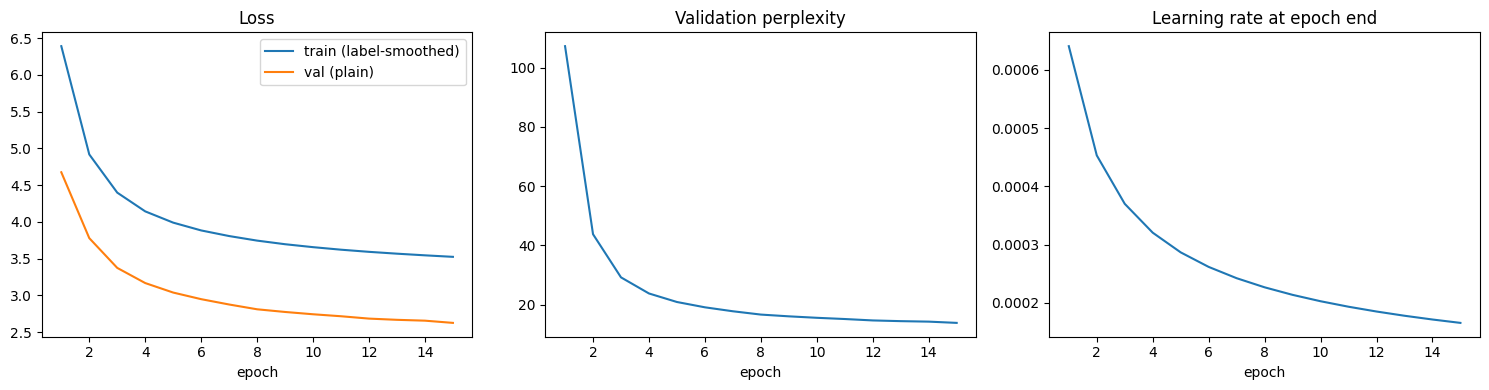

In [59]:
# loss curve
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ep = range(1, len(history["train_loss"]) + 1)

ax[0].plot(ep, history["train_loss"], label="train (label-smoothed)")
ax[0].plot(ep, history["val_loss"], label="val (plain)")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()

ax[1].plot(ep, history["val_ppl"]); ax[1].set_title("Validation perplexity"); ax[1].set_xlabel("epoch")
ax[2].plot(ep, history["lr"]); ax[2].set_title("Learning rate at epoch end"); ax[2].set_xlabel("epoch")

plt.tight_layout(); plt.show()

In [60]:
# resume later
ckpt = torch.load(os.path.join(CKPT_DIR, "last.pt"), map_location=device)
net.load_state_dict(ckpt["model"])
optimizer.load_state_dict(ckpt["optimizer"])
scheduler.load_state_dict(ckpt["scheduler"])
scaler.load_state_dict(ckpt["scaler"])
history, best_val, start_epoch = ckpt["history"], ckpt["best_val"], ckpt["epochs_done"]
print("Resumed. Epochs done:", start_epoch, "| best val loss:", round(best_val, 3))

# then continue:
# train_model(10)

Resumed. Epochs done: 15 | best val loss: 2.655


# phase 6
Greedy: always pick the single most likely next token.   Fast, but one early mistake can't be undone.
Beam  : keep the best K partial sentences at every step (K = beam width), finish them,
        then pick the best by total log-probability / length penalty.   Slower, usually better.

In [61]:
# load tokenizer and the best model
import os, sys, json, math
import torch, torch.nn.functional as F
import pandas as pd
import sentencepiece as spm

sys.path.insert(0, os.getcwd())
from model import Transformer, make_src_mask, make_tgt_mask

BASE_DIR      = os.getcwd()
PROCESSED_DIR = os.path.join(BASE_DIR, "processed_data")
CKPT_DIR      = os.path.join(BASE_DIR, "checkpoints")

sp = spm.SentencePieceProcessor(model_file=os.path.join(BASE_DIR, "tokenizer", "bpe.model"))
cfg = json.load(open(os.path.join(BASE_DIR, "config.json")))
PAD, BOS, EOS, MAX_LEN = cfg["pad_id"], cfg["bos_id"], cfg["eos_id"], cfg["max_len"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ckpt = torch.load(os.path.join(CKPT_DIR, "best.pt"), map_location=device)

net = Transformer(**ckpt["model_cfg"]).to(device)
net.load_state_dict(ckpt["model"])
net.eval()

print("Loaded best.pt from epoch:", ckpt["epochs_done"], "| device:", device)
print("Best val loss stored in file:", round(ckpt["best_val"], 3))

Loaded best.pt from epoch: 15 | device: cuda
Best val loss stored in file: 2.624


In [62]:
# greedy decoding
@torch.no_grad()
def encode_source(text):
    ids = [BOS] + sp.encode(text)[: MAX_LEN - 2] + [EOS]
    src = torch.tensor([ids], device=device)
    src_mask = make_src_mask(src, PAD)
    memory = net.encode(src, src_mask)          # English encoded only once
    return memory, src_mask


@torch.no_grad()
def greedy_translate(text, max_new=64):
    memory, src_mask = encode_source(text)
    out = [BOS]
    for _ in range(max_new):
        tgt = torch.tensor([out], device=device)
        logits = net.decode(tgt, memory, src_mask, make_tgt_mask(tgt, PAD))
        nxt = logits[0, -1].argmax().item()
        if nxt == EOS:
            break
        out.append(nxt)
    return sp.decode(out[1:])

In [63]:
# beam search
@torch.no_grad()
def beam_translate(text, beam=4, max_new=64, alpha=0.6):
    memory, src_mask = encode_source(text)

    beams = [([BOS], 0.0)]            # (tokens, sum of log-probs)
    finished = []

    for _ in range(max_new):
        seqs = torch.tensor([b[0] for b in beams], device=device)          # (nb, t)
        nb = seqs.size(0)
        mem = memory.expand(nb, -1, -1)
        sm  = src_mask.expand(nb, -1, -1, -1)
        logits = net.decode(seqs, mem, sm, make_tgt_mask(seqs, PAD))
        logp = F.log_softmax(logits[:, -1].float(), dim=-1)                # (nb, vocab)

        cands = []
        for bi, (toks, score) in enumerate(beams):
            top_lp, top_id = logp[bi].topk(beam)
            for lp, tid in zip(top_lp.tolist(), top_id.tolist()):
                cands.append((toks + [tid], score + lp))
        cands.sort(key=lambda x: x[1], reverse=True)

        beams = []
        for toks, score in cands:
            if toks[-1] == EOS:
                finished.append((toks, score))
            else:
                beams.append((toks, score))
            if len(beams) == beam:
                break

        if not beams or len(finished) >= beam:
            break

    if not finished:
        finished = beams

    def normalized(item):
        toks, score = item
        return score / (((5 + len(toks) - 1) / 6) ** alpha)

    best = max(finished, key=normalized)
    return sp.decode([t for t in best[0][1:] if t != EOS])

In [66]:
# testing the translation functions
tests = [
    "How are you?",
    "India is a very big country.",
    "I want to learn machine learning.",
    "The government announced a new education policy.",
    "Water is essential for life.",
    "He went to the market to buy vegetables.",
    "The weather is very nice today.",
    "Students should study hard to achieve success.",
    "The President addressed the nation on Independence Day.",
    "please closs the door.",
]

for t in tests:
    print("EN    :", t)
    print("Greedy:", greedy_translate(t))
    print("Beam 4:", beam_translate(t, beam=4))
    print()

EN    : How are you?
Greedy: आप कैसे हैं?
Beam 4: आप कैसे हैं?

EN    : India is a very big country.
Greedy: भारत एक बहुत बड़ा देश है।
Beam 4: भारत बहुत बड़ा देश है।

EN    : I want to learn machine learning.
Greedy: मैं मशीन सीखने के लिए चाहता हूँ।
Beam 4: मैं मशीन सीखना चाहता हूँ।

EN    : The government announced a new education policy.
Greedy: सरकार ने एक नई शिक्षा नीति की घोषणा की।
Beam 4: सरकार ने नई शिक्षा नीति की घोषणा की।

EN    : Water is essential for life.
Greedy: जीवन के लिए पानी आवश्यक है।
Beam 4: जीवन के लिए पानी आवश्यक है।

EN    : He went to the market to buy vegetables.
Greedy: वह सब्जियों के लिए बाजार में गया।
Beam 4: वह सब्जियों को खरीदने के लिए बाजार में गया।

EN    : The weather is very nice today.
Greedy: आज मौसम बहुत अच्छा है।
Beam 4: आज मौसम बहुत अच्छा है।

EN    : Students should study hard to achieve success.
Greedy: विद्यार्थियों को सफलता प्राप्त करने के लिए कठिन अध्ययन करना चाहिए।
Beam 4: विद्यार्थियों को सफलता प्राप्त करने के लिए कठोर अध्ययन करना चाहिए।

E

In [67]:
# compare with real references (validation set)
val_df = pd.read_parquet(os.path.join(PROCESSED_DIR, "val.parquet"))
sample = val_df.sample(8, random_state=1)

for en, hi in zip(sample["en"], sample["hi"]):
    print("EN    :", en)
    print("REF   :", hi)
    print("Greedy:", greedy_translate(en))
    print("Beam 4:", beam_translate(en, beam=4))
    print()

EN    : It covers an area of seventeen miles, east and west and about ten miles, north and south.
REF   : पूर्व से पश्चिम में यह सत्रह मील के क्षेत्र में और उत्तर से दक्षिण में लगभग दस मील में फैला हुआ है।
Greedy: यह 17 मील पूर्व और पश्चिम और लगभग दस मील उत्तर और दक्षिण के क्षेत्र को कवर करता है।
Beam 4: यह 17 मील पूर्व और पश्चिम तथा लगभग दस मील उत्तर और दक्षिण के क्षेत्र को कवर करता है।

EN    : These modules can be further coupled to form SPV array, to get desired power output to run the electrical appliances such as pumps.
REF   : जैसे उपकरणों को चलाने के लिए इच्छित शक्ति उत्पन्न करने के लिए इन मोड्यूल्स को आपस में जोड़कर सौर्य फोटोवोल्टिक सारणी बनाई जा सकती है।
Greedy: इन मॉड्यूलों को विशेष सरणी के रूप में और अधिक जोड़ दिया जा सकता है, ताकि बिजली की उपकरण जैसे पंपों को चलाने के लिए वांछित बिजली उत्पादन प्राप्त हो सके।
Beam 4: ये मॉड्यूल विशेष सरणी के रूप में और अधिक जोड़े जा सकते हैं, ताकि बिजली के उपकरण जैसे पंपों को चलाने के लिए वांछित बिजली उत्पादन मिल सके।

EN    : Now, one doe

In [68]:
# beam width and alpha experiments
text = "The government has launched a new scheme to help farmers across the country."
print("Greedy        :", greedy_translate(text))
for b in [2, 4, 8]:
    for a in [0.3, 0.6, 1.0]:
        print(f"beam={b}, alpha={a}:", beam_translate(text, beam=b, alpha=a))

Greedy        : सरकार ने देश भर के किसानों को मदद के लिए एक नई योजना शुरू की है।
beam=2, alpha=0.3: सरकार ने देश भर के किसानों को मदद के लिए एक नई योजना शुरू की है।
beam=2, alpha=0.6: सरकार ने देश भर के किसानों को मदद के लिए एक नई योजना शुरू की है।
beam=2, alpha=1.0: सरकार ने देश भर के किसानों को मदद के लिए एक नई योजना शुरू की है।
beam=4, alpha=0.3: सरकार ने देश भर के किसानों को मदद के लिए एक नई योजना शुरू की है।
beam=4, alpha=0.6: सरकार ने देश भर के किसानों को मदद के लिए एक नई योजना शुरू की है।
beam=4, alpha=1.0: सरकार ने देश भर के किसानों को मदद के लिए एक नई योजना शुरू की है।
beam=8, alpha=0.3: सरकार ने देश भर के किसानों को मदद के लिए एक नई योजना शुरू की है।
beam=8, alpha=0.6: सरकार ने देश भर के किसानों को मदद के लिए एक नई योजना शुरू की है।
beam=8, alpha=1.0: सरकार ने देश भर के किसानों को मदद के लिए एक नई योजना शुरू की है।


# phase 7

In [69]:
# load 
import re, time
import numpy as np
from sacrebleu.metrics import BLEU, CHRF

test_raw = pd.read_parquet(os.path.join(PROCESSED_DIR, "test.parquet"))
en_ids = sp.encode(test_raw["en"].tolist())
hi_ids = sp.encode(test_raw["hi"].tolist())

# same length rule as training data
keep = [i for i in range(len(test_raw))
        if len(en_ids[i]) <= MAX_LEN - 2 and len(hi_ids[i]) <= MAX_LEN - 2]

test_en  = [test_raw["en"].iloc[i] for i in keep]
test_ref = [test_raw["hi"].iloc[i] for i in keep]
test_src = [en_ids[i] for i in keep]

print("Test sentences:", len(test_en))

Test sentences: 4978


In [70]:
#fast batched greedy decoder and scoring helpers
@torch.no_grad()
def greedy_batch(src_ids_list, batch_size=64, max_new=70):
    order = sorted(range(len(src_ids_list)), key=lambda i: len(src_ids_list[i]))
    results = [None] * len(src_ids_list)

    for start in range(0, len(order), batch_size):
        idx = order[start:start + batch_size]
        seqs = [[BOS] + src_ids_list[i] + [EOS] for i in idx]
        L = max(len(s) for s in seqs)
        src = torch.tensor([s + [PAD] * (L - len(s)) for s in seqs], device=device)
        src_mask = make_src_mask(src, PAD)
        memory = net.encode(src, src_mask)

        ys = torch.full((len(idx), 1), BOS, dtype=torch.long, device=device)
        done = torch.zeros(len(idx), dtype=torch.bool, device=device)

        for _ in range(max_new):
            logits = net.decode(ys, memory, src_mask, make_tgt_mask(ys, PAD))
            nxt = logits[:, -1].argmax(-1)
            nxt = torch.where(done, torch.full_like(nxt, PAD), nxt)
            ys = torch.cat([ys, nxt.unsqueeze(1)], dim=1)
            done |= (nxt == EOS)
            if done.all():
                break

        for row, i in zip(ys.tolist(), idx):
            out = []
            for t in row[1:]:
                if t in (EOS, PAD):
                    break
                out.append(t)
            results[i] = sp.decode(out)
    return results


def norm(s):
    return re.sub(r"\s*([।॥])", r" \1", s).strip()      # space before danda

bleu_metric, chrf_metric = BLEU(), CHRF()

def score(hyps, refs):
    h = [norm(x) for x in hyps]
    r = [norm(x) for x in refs]
    return bleu_metric.corpus_score(h, [r]), chrf_metric.corpus_score(h, [r])

In [71]:
#greedy translation of the full test set, and scores
t0 = time.time()
greedy_out = greedy_batch(test_src)
elapsed = time.time() - t0
print(f"Translated {len(greedy_out)} sentences in {elapsed:.0f}s ({len(greedy_out) / elapsed:.0f} sentences/s)\n")

b, c = score(greedy_out, test_ref)
print("GREEDY  BLEU :", round(b.score, 2))
print("GREEDY  chrF :", round(c.score, 2))
print()
print(b)

Translated 4978 sentences in 48s (104 sentences/s)

GREEDY  BLEU : 19.65
GREEDY  chrF : 42.99

BLEU = 19.65 51.2/25.8/14.4/8.8 (BP = 0.972 ratio = 0.972 hyp_len = 83212 ref_len = 85616)


In [72]:
# greedy vs beam search (random subset of 300)
rng = np.random.RandomState(0)
sub = rng.choice(len(test_en), 300, replace=False)

sub_refs   = [test_ref[i] for i in sub]
sub_greedy = [greedy_out[i] for i in sub]

t0 = time.time()
sub_beam = [beam_translate(test_en[i], beam=4) for i in sub]
print(f"Beam search on 300 sentences took {time.time() - t0:.0f}s\n")

for name, hyps in [("greedy", sub_greedy), ("beam 4", sub_beam)]:
    b, c = score(hyps, sub_refs)
    print(f"{name:7s} BLEU: {b.score:5.2f} | chrF: {c.score:5.2f} | BP: {b.bp:.3f}")

Beam search on 300 sentences took 121s

greedy  BLEU: 20.31 | chrF: 43.91 | BP: 0.975
beam 4  BLEU: 21.81 | chrF: 45.35 | BP: 0.948


In [73]:
# quality by sentence length
src_words = [len(s.split()) for s in test_en]
buckets = [("1-8 words", 1, 8), ("9-15 words", 9, 15), ("16-25 words", 16, 25), ("26+ words", 26, 999)]

print(f"{'bucket':14s} {'count':>6s} {'BLEU':>7s} {'chrF':>7s}")
for name, lo, hi in buckets:
    idx = [i for i, w in enumerate(src_words) if lo <= w <= hi]
    if len(idx) < 20:
        continue
    b, c = score([greedy_out[i] for i in idx], [test_ref[i] for i in idx])
    print(f"{name:14s} {len(idx):6d} {b.score:7.2f} {c.score:7.2f}")

bucket          count    BLEU    chrF
1-8 words        1443   22.55   44.01
9-15 words       1609   20.72   42.80
16-25 words      1216   18.96   42.67
26+ words         710   18.59   43.16


In [74]:
#diagnosis (repetition, length, worst cases)

def has_repeat(s, n=3):
    w = s.split()
    grams = [tuple(w[i:i + n]) for i in range(len(w) - n + 1)]
    return len(grams) != len(set(grams))

rep_model = np.mean([has_repeat(s) for s in greedy_out]) * 100
rep_ref   = np.mean([has_repeat(s) for s in test_ref]) * 100
ratio = sum(len(s.split()) for s in greedy_out) / sum(len(s.split()) for s in test_ref)

print(f"Outputs with a repeated 3-gram : model {rep_model:.1f}%  |  references {rep_ref:.1f}%")
print(f"Output length / reference length (words): {ratio:.2f}\n")

# lowest sentence-level chrF (ignoring very short sentences)
scores = []
for i in range(len(test_en)):
    if src_words[i] >= 6:
        scores.append((chrf_metric.sentence_score(norm(greedy_out[i]), [norm(test_ref[i])]).score, i))
scores.sort()

print("=== 6 lowest-scoring sentences ===")
for sc, i in scores[:6]:
    print(f"chrF {sc:.1f}")
    print("EN :", test_en[i])
    print("REF:", test_ref[i])
    print("OUT:", greedy_out[i])
    print()

Outputs with a repeated 3-gram : model 4.3%  |  references 1.5%
Output length / reference length (words): 0.97

=== 6 lowest-scoring sentences ===
chrF 3.8
EN : Young Man Afraid Of His Horses
REF: जवान आदमी इसके घोड़ों से डरे
OUT: यंग मैन अफ्रिज, हिरण

chrF 4.8
EN : The Allies were on the offensive.
REF: मित्रराष्ट्र आक्रामक स्थिति में थे।
OUT: सभी लोग बहुत ही नीच थे।

chrF 4.8
EN : And (the clouds) that bear heavy weight of water;
REF: फिर बोझ उठाती है;
OUT: और वह खड़खड़ा देनेवाली पानी से होगा,

chrF 5.0
EN : They don 't mind being stung.
REF: इस कारण उनकी बात दूसरी है।
OUT: वे तो मन नहीं सोचते।

chrF 5.5
EN : Ensure that you consume a lot of drinkable beverages.
REF: सदैव लाल मास और पोलट्री के पतले टुकड़े चुनें।
OUT: कि तुम बहुत-से पेय मँगो

chrF 5.5
EN : sweet of laughter, sweet of speech,
REF: उसकी जमीन खिलते फूलों वाले वृक्षों से बहुत सुंदर ढकी हुई है,
OUT: हंसी, भाषण की मधुर,



In [75]:
# save all test translations
OUTPUT_DIR = os.path.join(BASE_DIR, "outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)

res = pd.DataFrame({"english": test_en, "reference": test_ref, "model_greedy": greedy_out})
res.to_csv(os.path.join(OUTPUT_DIR, "test_translations.csv"), index=False, encoding="utf-8-sig")
print("Saved:", os.path.join(OUTPUT_DIR, "test_translations.csv"))

Saved: e:\Pyhton code\Deep Learning\Natural Language Processing (NLP)\translation project\outputs\test_translations.csv


In [76]:
#export the slim inference model (no optimizer, scheduler, scaler, history, etc.)
import os, torch

BASE_DIR = os.getcwd()
ckpt = torch.load(os.path.join(BASE_DIR, "checkpoints", "best.pt"), map_location="cpu")

os.makedirs(os.path.join(BASE_DIR, "exports"), exist_ok=True)
out_path = os.path.join(BASE_DIR, "exports", "model_inference.pt")

torch.save({
    "model": ckpt["model"],
    "model_cfg": ckpt["model_cfg"],
    "info": {
        "epochs": ckpt["epochs_done"],
        "val_loss": round(ckpt["best_val"], 3),
        "test_bleu": 19.65,        # greedy scores from Phase 7
        "test_chrf": 42.99,
        "train_pairs": 298488,
    },
}, out_path)

print("Saved:", out_path)
print("Size :", round(os.path.getsize(out_path) / 1e6, 1), "MB")
print("Info :", torch.load(out_path, map_location="cpu")["info"])

Saved: e:\Pyhton code\Deep Learning\Natural Language Processing (NLP)\translation project\exports\model_inference.pt
Size : 54.3 MB
Info : {'epochs': 15, 'val_loss': 2.624, 'test_bleu': 19.65, 'test_chrf': 42.99, 'train_pairs': 298488}


In [77]:
# %%
import os
with open("app.py", encoding="utf-8") as f:
    lines = f.read().splitlines()

print("Lines in app.py :", len(lines))
print("First 3 lines   :", lines[:3])
print("Last 3 lines    :", lines[-3:])
print("Lines using os. :", [i + 1 for i, l in enumerate(lines) if "os." in l])

Lines in app.py : 88
First 3 lines   : ['import html', 'import time', 'import streamlit as st']
Last 3 lines    : ['st.divider()', 'st.caption("This is a learning project. It works best on short, everyday sentences. "', '           "Rare words, names and idioms may be translated incorrectly.")']
Lines using os. : []


In [79]:
# %%
import os, re

src = open("translator.py", encoding="utf-8").read()
m = re.search(r"translator_code\s*=\s*r'''(.*?)'''", src, re.S)

if m:
    with open("translator.py", "w", encoding="utf-8") as f:
        f.write(m.group(1).lstrip())
    print("Fixed translator.py")
else:
    print("Pattern not found, so the file may already be clean or different")

lines = open("translator.py", encoding="utf-8").read().splitlines()
print("Lines      :", len(lines))
print("First line :", lines[0])
print("Last 3     :", lines[-3:])

Pattern not found, so the file may already be clean or different
Lines      : 113
First line : import os, re, json
Last 3     : ['            "pairs": pairs,', '            "truncated": any_truncated,', '        }']


In [80]:
# %%
import sys, importlib, time
sys.path.insert(0, os.getcwd())
import translator
importlib.reload(translator)

tr = translator.Translator()
print("Device :", tr.device, "| params:", f"{tr.n_params:,}")
print("Info   :", tr.info)
print()

text = "The government announced a new education policy. Students should study hard to achieve success. Water is essential for life."

for mode in ["greedy", "beam"]:
    t0 = time.time()
    res = tr.translate(text, mode=mode)
    print(f"[{mode}]  {time.time() - t0:.2f}s")
    for en, hi in res["pairs"]:
        print("  EN:", en)
        print("  HI:", hi)
    print()

Device : cuda | params: 13,517,824
Info   : {'epochs': 15, 'val_loss': 2.624, 'test_bleu': 19.65, 'test_chrf': 42.99, 'train_pairs': 298488}

[greedy]  0.69s
  EN: The government announced a new education policy.
  HI: सरकार ने एक नई शिक्षा नीति की घोषणा की।
  EN: Students should study hard to achieve success.
  HI: विद्यार्थियों को सफलता प्राप्त करने के लिए कठिन अध्ययन करना चाहिए।
  EN: Water is essential for life.
  HI: जीवन के लिए पानी आवश्यक है।

[beam]  0.74s
  EN: The government announced a new education policy.
  HI: सरकार ने नई शिक्षा नीति की घोषणा की।
  EN: Students should study hard to achieve success.
  HI: विद्यार्थियों को सफलता प्राप्त करने के लिए कठोर अध्ययन करना चाहिए।
  EN: Water is essential for life.
  HI: जीवन के लिए पानी आवश्यक है।



In [81]:
# %%
import os, sys, math, importlib
import numpy as np
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt

sys.path.insert(0, os.getcwd())
import translator
importlib.reload(translator)
from model import MultiHeadAttention, make_src_mask, make_tgt_mask

tr = translator.Translator()
net, sp, device = tr.net, tr.sp, tr.device
PAD, BOS, EOS = tr.PAD, tr.BOS, tr.EOS
D_MODEL = net.d_model
net.eval()

# make every attention layer remember its attention weights
for m in net.modules():
    if isinstance(m, MultiHeadAttention):
        m.save_attn = True

plt.rcParams["font.family"] = ["Nirmala UI", "Mangal", "DejaVu Sans"]
HINDI_LABELS = True        # set False if Hindi letters look broken in the plots


def labels(ids, hindi=False, offset=0):
    out = []
    for k, i in enumerate(ids):
        p = sp.id_to_piece(int(i)).replace("▁", "") or "_"
        if hindi and not HINDI_LABELS and not p.startswith("<"):
            p = f"h{k + offset}"
        out.append(p)
    return out


def plot_heads(att, xl, yl, title, ncols=4, cmap="Blues"):
    n = att.shape[0]
    nrows = (n + ncols - 1) // ncols
    fig, axs = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4 * nrows))
    for k, a in enumerate(np.array(axs).ravel()):
        if k >= n:
            a.axis("off")
            continue
        a.imshow(att[k], cmap=cmap, vmin=0, vmax=1, aspect="auto")
        a.set_title(f"head {k + 1}", fontsize=10)
        a.set_xticks(range(len(xl))); a.set_xticklabels(xl, rotation=90, fontsize=7)
        a.set_yticks(range(len(yl))); a.set_yticklabels(yl, fontsize=7)
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()


print("Model ready on", device)

Model ready on cuda


In [82]:
# %%
SENTENCE = "The government announced a new education policy."


@torch.no_grad()
def run_sentence(sentence, max_new=60):
    ids = sp.encode(sentence)[: tr.max_len - 2]
    src = torch.tensor([[BOS] + ids + [EOS]], device=device)
    src_mask = make_src_mask(src, PAD)
    memory = net.encode(src, src_mask)                      # encoder runs once

    out = [BOS]                                             # greedy decoding, keeping ids
    for _ in range(max_new):
        tgt = torch.tensor([out], device=device)
        logits = net.decode(tgt, memory, src_mask, make_tgt_mask(tgt, PAD))
        nxt = logits[0, -1].argmax().item()
        out.append(nxt)
        if nxt == EOS:
            break

    tgt_in = torch.tensor([out[:-1]], device=device)        # what the decoder read
    tgt_out = out[1:]                                       # what it produced
    logits = net.decode(tgt_in, memory, src_mask, make_tgt_mask(tgt_in, PAD))  # clean pass for stored attention
    probs = F.softmax(logits[0].float(), dim=-1)
    return dict(src=src, src_mask=src_mask, tgt_in=tgt_in, tgt_out=tgt_out, probs=probs, memory=memory)


R = run_sentence(SENTENCE)
src_ids = R["src"][0].tolist()
tgt_in_ids = R["tgt_in"][0].tolist()
tgt_out_ids = R["tgt_out"]
S, T = len(src_ids), len(tgt_in_ids)

print("ENGLISH :", SENTENCE)
print("HINDI   :", sp.decode([t for t in tgt_out_ids if t != EOS]))

print("\nSOURCE TOKENS (encoder input)")
print("  pos | piece        | id")
for k, (p, i) in enumerate(zip(labels(src_ids), src_ids)):
    print(f"  {k:3d} | {p:12s} | {i}")

print("\nDECODER: input word -> word it must predict")
print("  pos | input         -> predicted      (Hindi token #)")
for k, (a, b) in enumerate(zip(labels(tgt_in_ids), labels(tgt_out_ids))):
    print(f"  {k:3d} | {a:13s} -> {b:14s} (#{k + 1})")


# ---------- tensor shapes at every stage ----------
def shapes_of(modules, fn):
    log, hooks = [], []
    for name, m in modules:
        hooks.append(m.register_forward_hook(lambda mod, i, o, n=name: log.append((n, tuple(o.shape)))))
    with torch.no_grad():
        fn()
    for h in hooks:
        h.remove()
    return log


enc_log = shapes_of(
    [("Embedding lookup", net.embed), ("+ Positional encoding", net.pos)]
    + [(f"Encoder layer {i + 1}", l) for i, l in enumerate(net.encoder.layers)]
    + [("Final LayerNorm = MEMORY", net.encoder)],
    lambda: net.encode(R["src"], R["src_mask"]))

dec_log = shapes_of(
    [("Embedding lookup", net.embed), ("+ Positional encoding", net.pos)]
    + [(f"Decoder layer {i + 1}", l) for i, l in enumerate(net.decoder.layers)]
    + [("Final LayerNorm", net.decoder), ("Output layer (scores)", net.out_proj)],
    lambda: net.decode(R["tgt_in"], R["memory"], R["src_mask"], make_tgt_mask(R["tgt_in"], PAD)))

print("\nENCODER shapes  (batch, words, features)")
for n, s in enc_log:
    print(f"  {n:28s} {s}")
print("\nDECODER shapes")
for n, s in dec_log:
    print(f"  {n:28s} {s}")

ENGLISH : The government announced a new education policy.
HINDI   : सरकार ने एक नई शिक्षा नीति की घोषणा की।

SOURCE TOKENS (encoder input)
  pos | piece        | id
    0 | <bos>        | 2
    1 | The          | 122
    2 | government   | 1929
    3 | announced    | 9583
    4 | a            | 7
    5 | new          | 818
    6 | education    | 2130
    7 | policy       | 3020
    8 | .            | 23901
    9 | <eos>        | 3

DECODER: input word -> word it must predict
  pos | input         -> predicted      (Hindi token #)
    0 | <bos>         -> सरकार          (#1)
    1 | सरकार         -> ने             (#2)
    2 | ने            -> एक             (#3)
    3 | एक            -> नई             (#4)
    4 | नई            -> शिक्षा         (#5)
    5 | शिक्षा        -> नीति           (#6)
    6 | नीति          -> की             (#7)
    7 | की            -> घोषणा          (#8)
    8 | घोषणा         -> की             (#9)
    9 | की            -> ।              (#10)
   10 | ।   

findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not

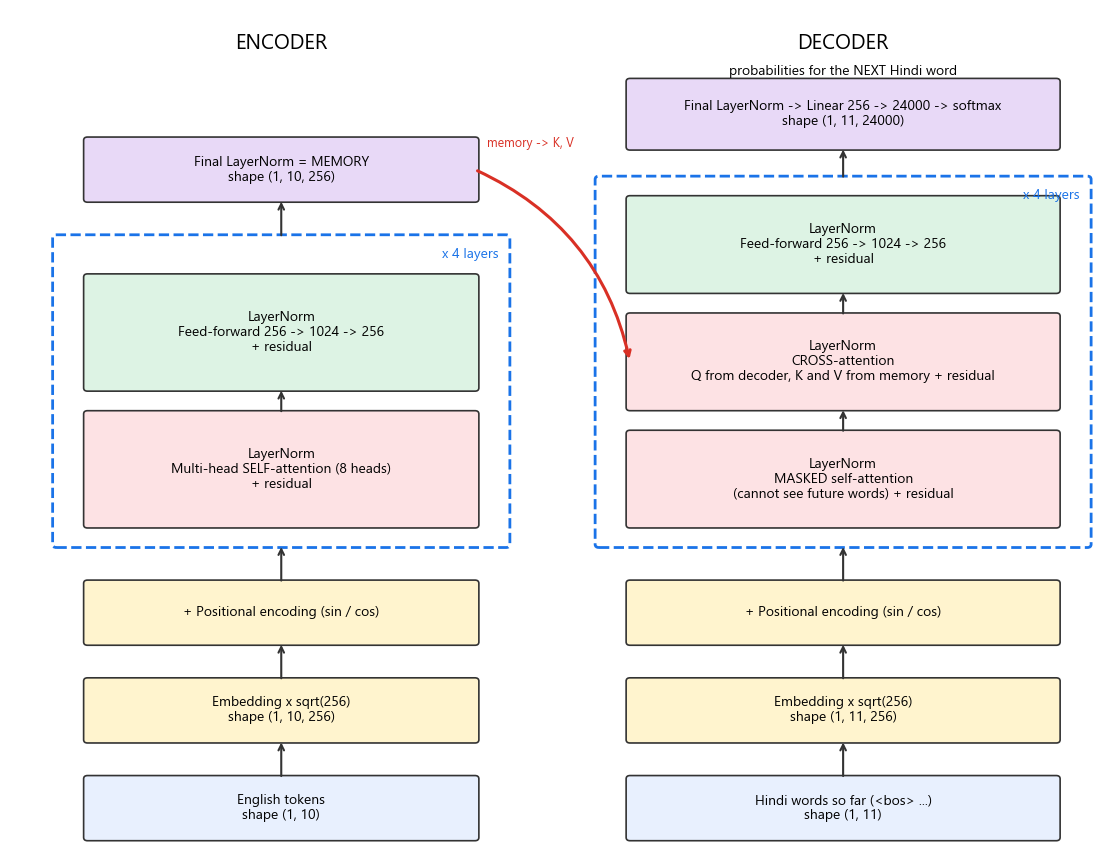

In [83]:
# %%
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(14, 11))
ax.set_xlim(0, 14); ax.set_ylim(0, 13); ax.axis("off")
C = dict(io="#E8F0FE", emb="#FFF4CE", attn="#FDE2E4", ff="#DDF3E4", out="#E8D9F7")


def box(x, y, w, h, text, color, fs=10):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=color, ec="#333", lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)


def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=1.5, color="#333"))


# ---------------- ENCODER ----------------
ax.text(3.5, 12.4, "ENCODER", ha="center", fontsize=15, weight="bold")
box(1, 0.3, 5, 0.9, f"English tokens\nshape (1, {S})", C["io"]);                      arrow(3.5, 1.2, 3.5, 1.8)
box(1, 1.8, 5, 0.9, f"Embedding x sqrt(256)\nshape (1, {S}, 256)", C["emb"]);          arrow(3.5, 2.7, 3.5, 3.3)
box(1, 3.3, 5, 0.9, "+ Positional encoding (sin / cos)", C["emb"]);                    arrow(3.5, 4.2, 3.5, 4.8)
ax.add_patch(FancyBboxPatch((0.6, 4.8), 5.8, 4.7, boxstyle="round,pad=0.05", fc="none", ec="#1a73e8", lw=2, ls="--"))
ax.text(6.3, 9.2, "x 4 layers", ha="right", fontsize=10, color="#1a73e8")
box(1, 5.1, 5, 1.7, "LayerNorm\nMulti-head SELF-attention (8 heads)\n+ residual", C["attn"]);  arrow(3.5, 6.8, 3.5, 7.2)
box(1, 7.2, 5, 1.7, "LayerNorm\nFeed-forward 256 -> 1024 -> 256\n+ residual", C["ff"])
arrow(3.5, 9.5, 3.5, 10.1)
box(1, 10.1, 5, 0.9, f"Final LayerNorm = MEMORY\nshape (1, {S}, 256)", C["out"])

# ---------------- DECODER ----------------
ax.text(10.75, 12.4, "DECODER", ha="center", fontsize=15, weight="bold")
box(8, 0.3, 5.5, 0.9, f"Hindi words so far (<bos> ...)\nshape (1, {T})", C["io"]);       arrow(10.75, 1.2, 10.75, 1.8)
box(8, 1.8, 5.5, 0.9, f"Embedding x sqrt(256)\nshape (1, {T}, 256)", C["emb"]);          arrow(10.75, 2.7, 10.75, 3.3)
box(8, 3.3, 5.5, 0.9, "+ Positional encoding (sin / cos)", C["emb"]);                    arrow(10.75, 4.2, 10.75, 4.8)
ax.add_patch(FancyBboxPatch((7.6, 4.8), 6.3, 5.6, boxstyle="round,pad=0.05", fc="none", ec="#1a73e8", lw=2, ls="--"))
ax.text(13.8, 10.1, "x 4 layers", ha="right", fontsize=10, color="#1a73e8")
box(8, 5.1, 5.5, 1.4, "LayerNorm\nMASKED self-attention\n(cannot see future words) + residual", C["attn"]);  arrow(10.75, 6.5, 10.75, 6.9)
box(8, 6.9, 5.5, 1.4, "LayerNorm\nCROSS-attention\nQ from decoder, K and V from memory + residual", C["attn"]);  arrow(10.75, 8.3, 10.75, 8.7)
box(8, 8.7, 5.5, 1.4, "LayerNorm\nFeed-forward 256 -> 1024 -> 256\n+ residual", C["ff"])
arrow(10.75, 10.4, 10.75, 10.9)
box(8, 10.9, 5.5, 1.0, f"Final LayerNorm -> Linear 256 -> 24000 -> softmax\nshape (1, {T}, 24000)", C["out"])

# memory goes into the decoder's cross-attention
ax.annotate("", xy=(8.0, 7.6), xytext=(6.0, 10.55),
            arrowprops=dict(arrowstyle="->", lw=2.2, color="#d93025", connectionstyle="arc3,rad=-0.25"))
ax.text(6.15, 10.9, "memory -> K, V", fontsize=9, color="#d93025")

ax.text(10.75, 12.0, "probabilities for the NEXT Hindi word", ha="center", fontsize=10, style="italic")
plt.show()

findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not

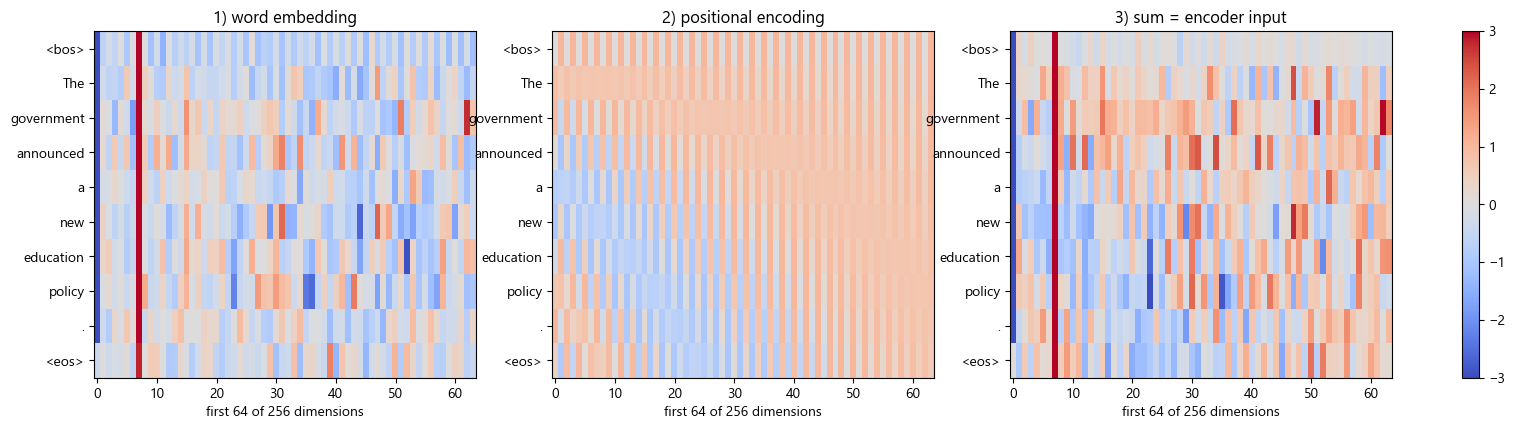

findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not

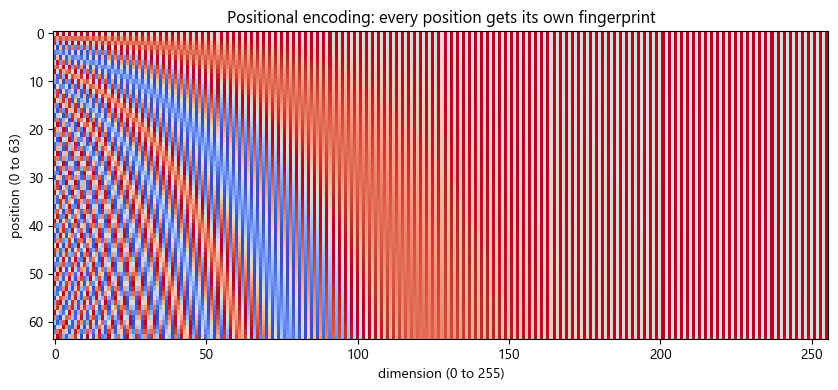

Token "The" -> id 122 -> a vector of 256 numbers
embedding[:8] : [-12.98  -0.28  -0.59  -0.52  -0.82   0.6   -0.21   9.78]
position [:8] : [0.84 0.54 0.8  0.6  0.76 0.65 0.72 0.69]
sum      [:8] : [-12.14   0.26   0.21   0.08  -0.06   1.25   0.52  10.47]


In [84]:
# %%
with torch.no_grad():
    emb = net.embed(R["src"]) * math.sqrt(D_MODEL)       # (1, S, 256)
    pe = net.pos.pe[:, :S]                               # (1, S, 256)
    x0 = emb + pe                                        # what enters encoder layer 1

fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
for a, data, title in zip(axs, [emb, pe, x0],
                          ["1) word embedding", "2) positional encoding", "3) sum = encoder input"]):
    im = a.imshow(data[0].cpu().numpy()[:, :64], aspect="auto", cmap="coolwarm", vmin=-3, vmax=3)
    a.set_yticks(range(S)); a.set_yticklabels(labels(src_ids))
    a.set_xlabel("first 64 of 256 dimensions"); a.set_title(title)
plt.colorbar(im, ax=axs, fraction=0.02)
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.imshow(net.pos.pe[0, :64].cpu().numpy(), aspect="auto", cmap="coolwarm")
ax.set_xlabel("dimension (0 to 255)"); ax.set_ylabel("position (0 to 63)")
ax.set_title("Positional encoding: every position gets its own fingerprint")
plt.show()

k = 1
print(f'Token "{labels(src_ids)[k]}" -> id {src_ids[k]} -> a vector of {D_MODEL} numbers')
print("embedding[:8] :", emb[0, k, :8].cpu().numpy().round(2))
print("position [:8] :", pe[0, k, :8].cpu().numpy().round(2))
print("sum      [:8] :", x0[0, k, :8].cpu().numpy().round(2))

findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.


STEP 1  input after LayerNorm       : (1, 10, 256)
STEP 2  Q, K, V (8 heads, 32 each)  : (1, 8, 10, 32)
STEP 3  scores = Q K^T / sqrt(32)   : (1, 8, 10, 10)
STEP 4  softmax (each row sums to 1): (1, 8, 10, 10) | row sum = 1.0
STEP 5  weights @ V                 : (1, 8, 10, 32)
        8 heads joined -> (1, 10 , 256) -> output Linear -> + residual

Matches the attention stored by the real model: True


findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not

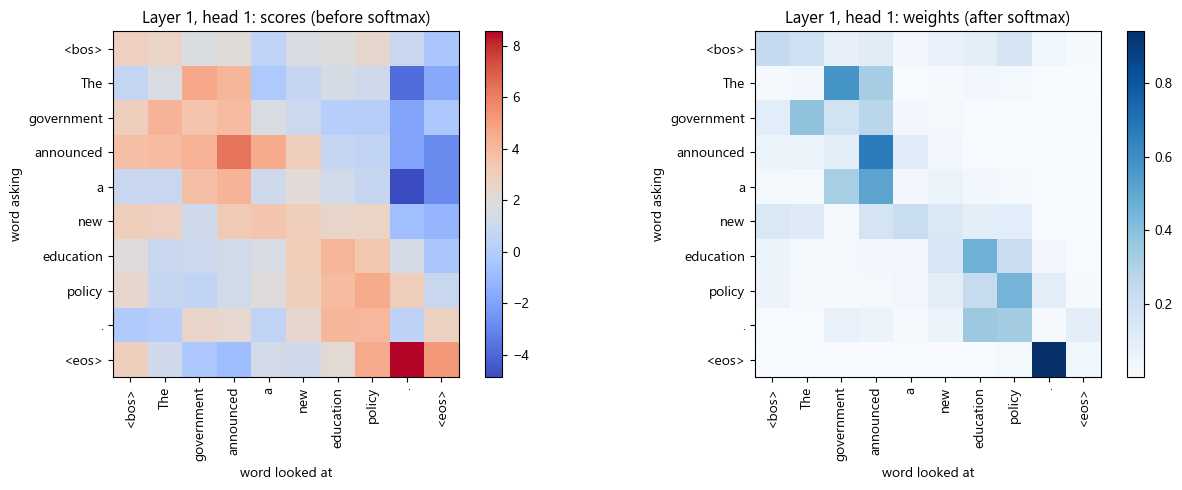


The word "announced" (layer 1, head 1) pays attention to:
   announced      0.67  ##########################
   a              0.11  ####
   government     0.09  ###
   The            0.06  ##
   <bos>          0.05  ##
   new            0.02  


In [85]:
# %%
LAYER, HEAD, QUERY_POS = 0, 0, 3     # change these and rerun: which layer, which head, which word

layer = net.encoder.layers[LAYER]
sa = layer.self_attn
nh, d_k = sa.h, sa.d_k
lab = labels(src_ids)

with torch.no_grad():
    x = x0
    for l in net.encoder.layers[:LAYER]:
        x = l(x, R["src_mask"])
    hn = layer.norm1(x)                                              # (1, S, 256)
    Q = sa.w_q(hn).view(1, S, nh, d_k).transpose(1, 2)               # (1, 8, S, 32)
    K = sa.w_k(hn).view(1, S, nh, d_k).transpose(1, 2)
    V = sa.w_v(hn).view(1, S, nh, d_k).transpose(1, 2)
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d_k)                # (1, 8, S, S)
    weights = F.softmax(scores, dim=-1)
    mixed = weights @ V                                              # (1, 8, S, 32)

print("STEP 1  input after LayerNorm       :", tuple(hn.shape))
print("STEP 2  Q, K, V (8 heads, 32 each)  :", tuple(Q.shape))
print("STEP 3  scores = Q K^T / sqrt(32)   :", tuple(scores.shape))
print("STEP 4  softmax (each row sums to 1):", tuple(weights.shape),
      "| row sum =", round(weights[0, HEAD, QUERY_POS].sum().item(), 3))
print("STEP 5  weights @ V                 :", tuple(mixed.shape))
print("        8 heads joined -> (1,", S, ", 256) -> output Linear -> + residual")
print("\nMatches the attention stored by the real model:",
      torch.allclose(weights, sa.attn_weights, atol=1e-5))

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for a, data, title, cmap in [(axs[0], scores[0, HEAD], "scores (before softmax)", "coolwarm"),
                             (axs[1], weights[0, HEAD], "weights (after softmax)", "Blues")]:
    im = a.imshow(data.cpu().numpy(), cmap=cmap)
    a.set_xticks(range(S)); a.set_xticklabels(lab, rotation=90)
    a.set_yticks(range(S)); a.set_yticklabels(lab)
    a.set_title(f"Layer {LAYER + 1}, head {HEAD + 1}: {title}")
    a.set_xlabel("word looked at"); a.set_ylabel("word asking")
    plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

w = weights[0, HEAD, QUERY_POS].cpu().numpy()
print(f'\nThe word "{lab[QUERY_POS]}" (layer {LAYER + 1}, head {HEAD + 1}) pays attention to:')
for j in np.argsort(-w)[:6]:
    print(f"   {lab[j]:14s} {w[j]:.2f}  " + "#" * int(w[j] * 40))

findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not

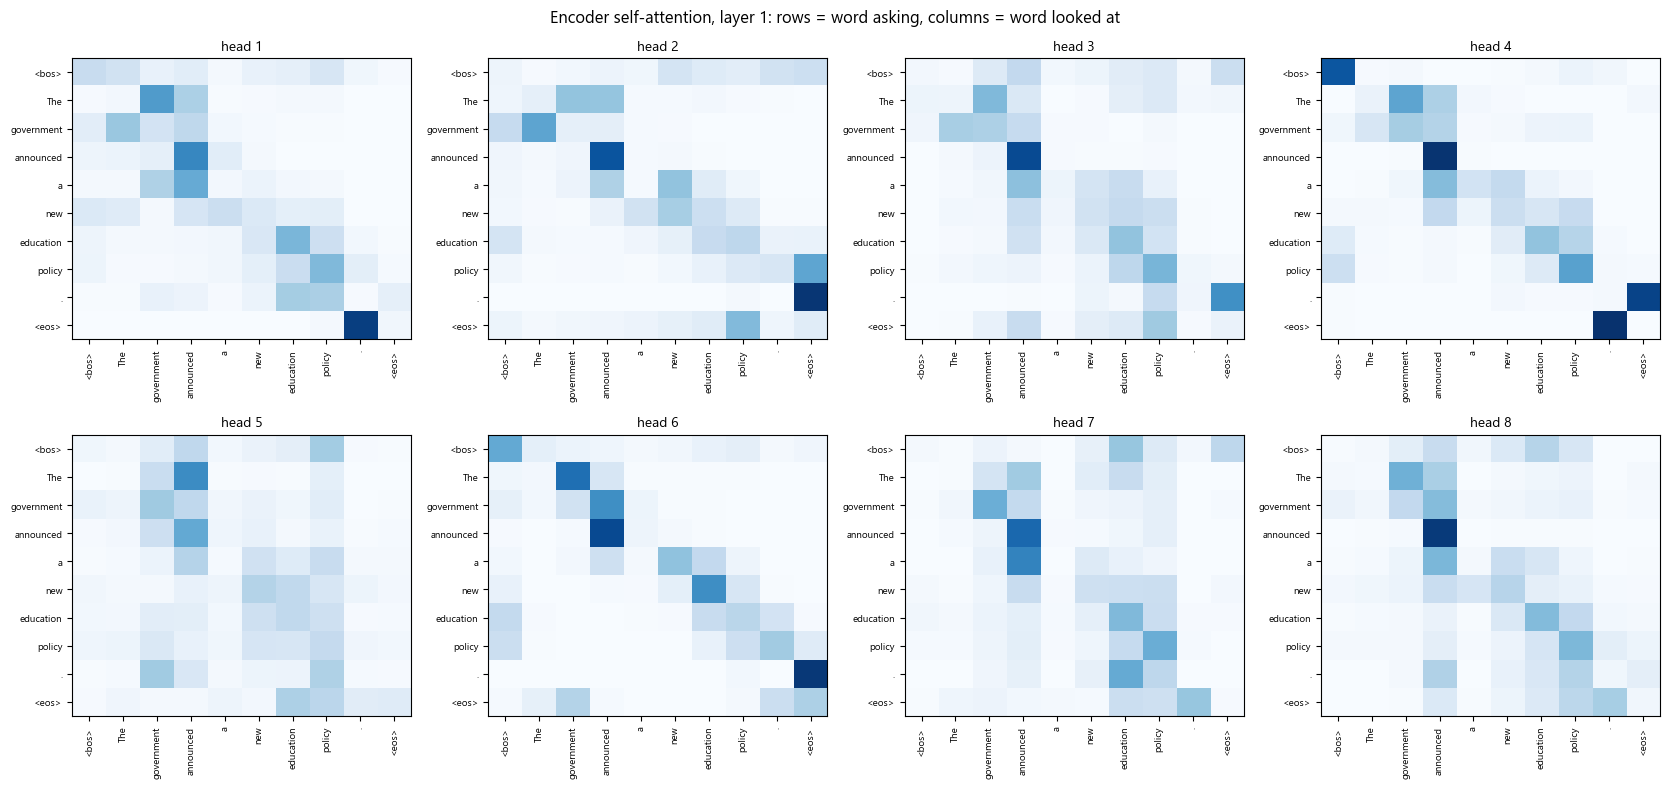

findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not

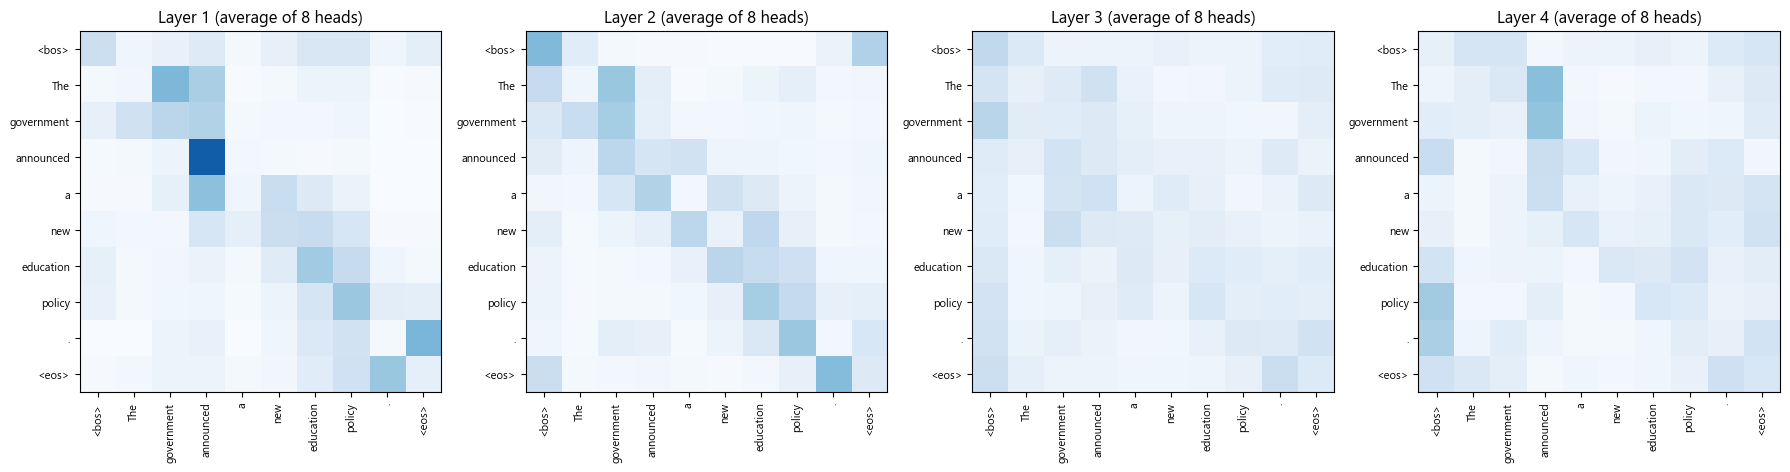

In [86]:
# %%
LAYER = 0                                # which layer to show in detail (0 to 3)
src_lab = labels(src_ids)
enc_att = [l.self_attn.attn_weights[0].cpu().numpy() for l in net.encoder.layers]   # each (8, S, S)

plot_heads(enc_att[LAYER], src_lab, src_lab,
           f"Encoder self-attention, layer {LAYER + 1}: rows = word asking, columns = word looked at")

fig, axs = plt.subplots(1, len(enc_att), figsize=(4.5 * len(enc_att), 4.5))
for k, (a, att) in enumerate(zip(axs, enc_att)):
    a.imshow(att.mean(0), cmap="Blues", vmin=0, vmax=1)
    a.set_title(f"Layer {k + 1} (average of 8 heads)")
    a.set_xticks(range(S)); a.set_xticklabels(src_lab, rotation=90, fontsize=8)
    a.set_yticks(range(S)); a.set_yticklabels(src_lab, fontsize=8)
plt.tight_layout(); plt.show()

findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.


At every step the decoder reads the words so far and scores all 24,000 tokens.

Step  1: after [<bos>]
         top-5 -> सरकार 0.88   सरकारी 0.05   इस 0.00   शासन 0.00   गवर्न 0.00
         chosen -> सरकार  (p = 0.88)

Step  2: after [<bos> सरकार]
         top-5 -> ने 0.92   द्वारा 0.01   की 0.01   के 0.00   ने 0.00
         chosen -> ने  (p = 0.92)

Step  3: after [<bos> सरकार ने]
         top-5 -> एक 0.37   नई 0.28   नयी 0.06   शिक्षा 0.04   नए 0.03
         chosen -> एक  (p = 0.37)

Step  4: after [<bos> सरकार ने एक]
         top-5 -> नई 0.71   नयी 0.18   नए 0.03   नया 0.01   नये 0.01
         chosen -> नई  (p = 0.71)

Step  5: after [<bos> सरकार ने एक नई]
         top-5 -> शिक्षा 0.93   शैक्षिक 0.00   पढ़ाई 0.00   विद्या 0.00   - 0.00
         chosen -> शिक्षा  (p = 0.93)

Step  6: after [<bos> सरकार ने एक नई शिक्षा]
         top-5 -> नीति 0.97   की 0.00   पॉलिसी 0.00   शिक्षा 0.00   - 0.00
         chosen -> नीति  (p = 0.97)

Step  7: after [<bos> सरकार ने एक नई शिक्षा नीति]
     

findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not

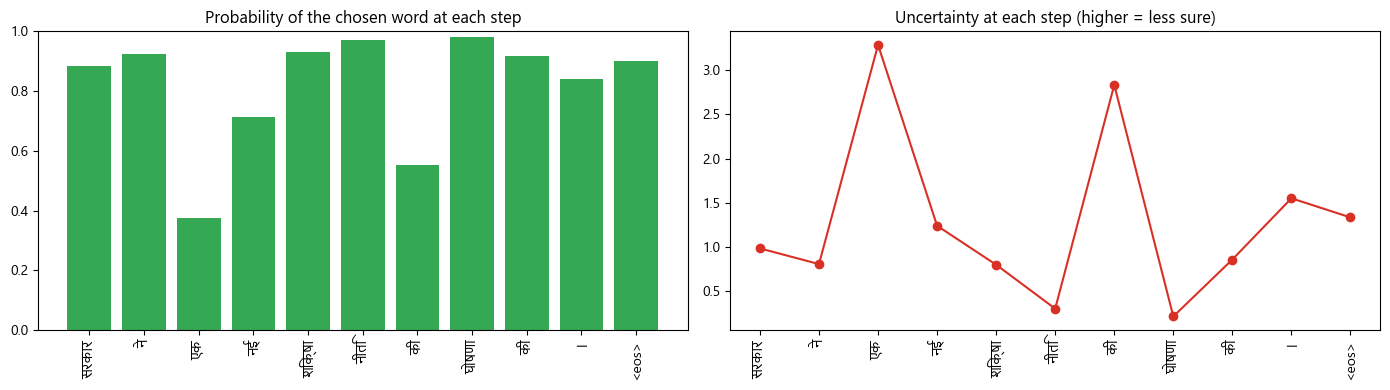

In [87]:
# %%
probs = R["probs"].cpu().numpy()                       # (T, 24000)
in_lab = labels(tgt_in_ids)
out_lab = labels(tgt_out_ids)
TOPK = 5

print("At every step the decoder reads the words so far and scores all 24,000 tokens.\n")
for t in range(T):
    top = np.argsort(-probs[t])[:TOPK]
    print(f"Step {t + 1:2d}: after [{' '.join(in_lab[:t + 1])}]")
    print("         top-5 ->", "   ".join(f"{labels([i])[0]} {probs[t, i]:.2f}" for i in top))
    print(f"         chosen -> {out_lab[t]}  (p = {probs[t, tgt_out_ids[t]]:.2f})\n")

chosen_p = [probs[t, tgt_out_ids[t]] for t in range(T)]
entropy = -(probs * np.log(probs + 1e-12)).sum(1)
plot_lab = labels(tgt_out_ids, hindi=True, offset=1)

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].bar(range(T), chosen_p, color="#34a853")
axs[0].set_xticks(range(T)); axs[0].set_xticklabels(plot_lab, rotation=90)
axs[0].set_ylim(0, 1); axs[0].set_title("Probability of the chosen word at each step")
axs[1].plot(entropy, marker="o", color="#d93025")
axs[1].set_xticks(range(T)); axs[1].set_xticklabels(plot_lab, rotation=90)
axs[1].set_title("Uncertainty at each step (higher = less sure)")
plt.tight_layout(); plt.show()

findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not

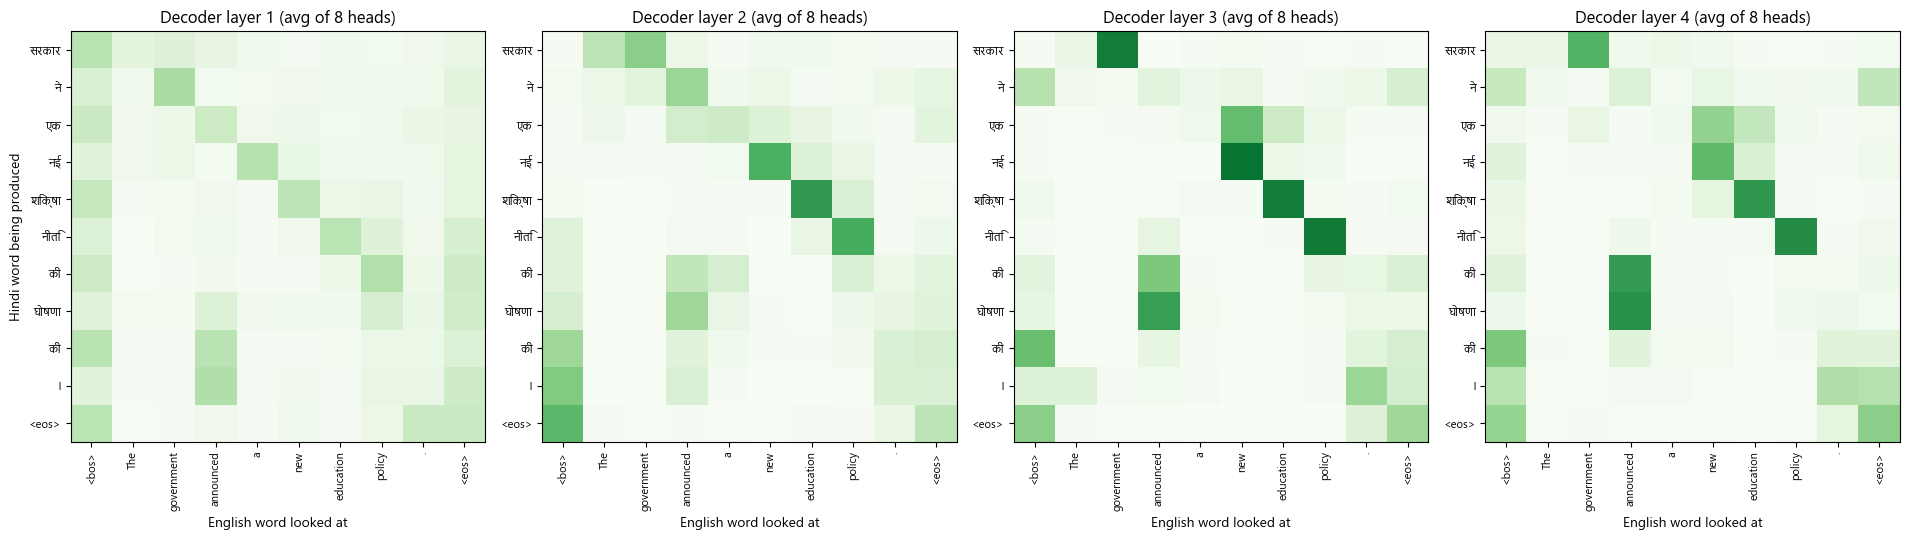

Which English word got the most attention for each Hindi word? (last layer, average of heads)

  सरकार          <- government     (0.58)
  ने             <- <eos>          (0.27)
  एक             <- new            (0.42)
  नई             <- new            (0.55)
  शिक्षा         <- education      (0.70)
  नीति           <- policy         (0.74)
  की             <- announced      (0.69)
  घोषणा          <- announced      (0.73)
  की             <- <bos>          (0.47)
  ।              <- .              (0.32)
  <eos>          <- <eos>          (0.44)


findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not

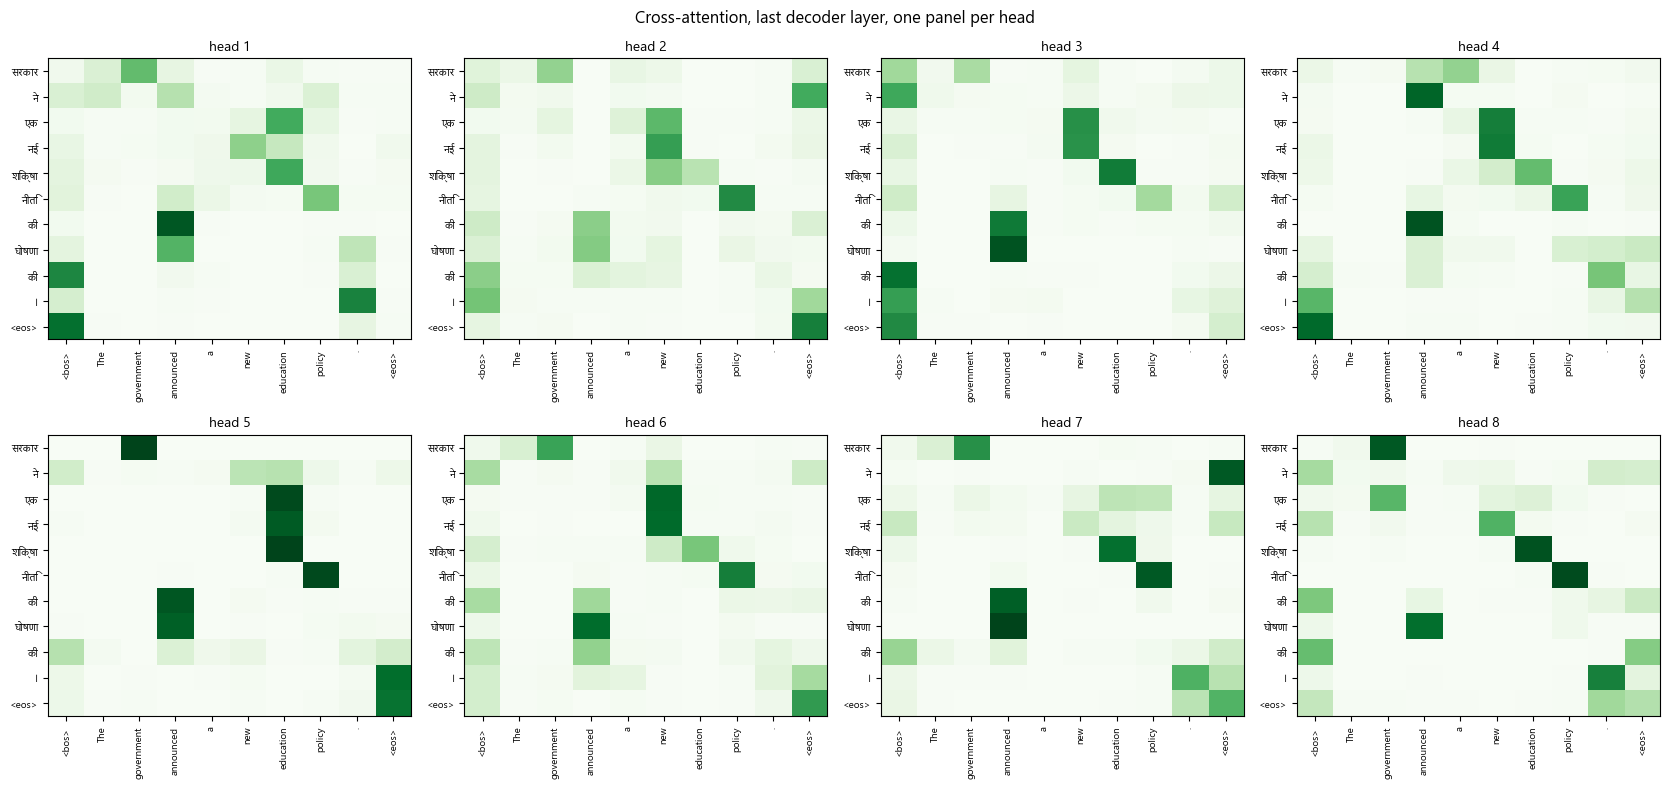

In [88]:
# %%
src_lab = labels(src_ids)
tgt_lab = labels(tgt_out_ids, hindi=True, offset=1)
cross = [l.cross_attn.attn_weights[0].cpu().numpy() for l in net.decoder.layers]   # each (8, T, S)

fig, axs = plt.subplots(1, len(cross), figsize=(4.8 * len(cross), 5.5))
for k, (a, att) in enumerate(zip(axs, cross)):
    a.imshow(att.mean(0), cmap="Greens", vmin=0, vmax=1, aspect="auto")
    a.set_title(f"Decoder layer {k + 1} (avg of 8 heads)")
    a.set_xticks(range(S)); a.set_xticklabels(src_lab, rotation=90, fontsize=8)
    a.set_yticks(range(T)); a.set_yticklabels(tgt_lab, fontsize=8)
    a.set_xlabel("English word looked at")
axs[0].set_ylabel("Hindi word being produced")
plt.tight_layout(); plt.show()

last = cross[-1].mean(0)
real_out = labels(tgt_out_ids)
print("Which English word got the most attention for each Hindi word? (last layer, average of heads)\n")
for t in range(T):
    j = last[t].argmax()
    print(f"  {real_out[t]:14s} <- {src_lab[j]:14s} ({last[t, j]:.2f})")

plot_heads(cross[-1], src_lab, tgt_lab, "Cross-attention, last decoder layer, one panel per head", cmap="Greens")

findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not found.
findfont: Font family 'Mangal' not

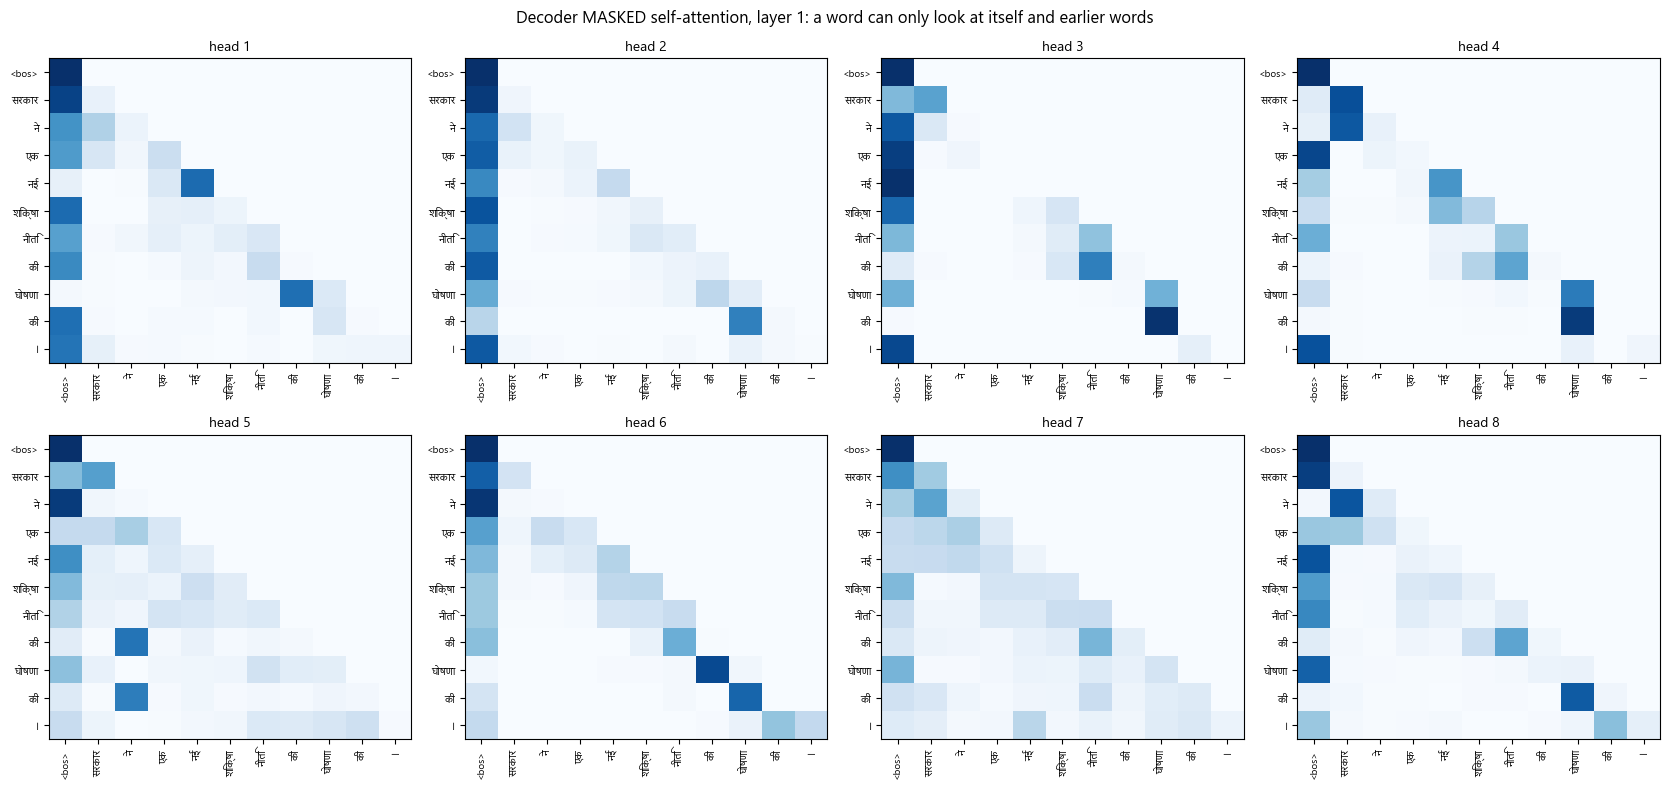

Total attention on FUTURE words (must be 0): 0.0


In [89]:
# %%
dec_self = [l.self_attn.attn_weights[0].cpu().numpy() for l in net.decoder.layers]   # each (8, T, T)
in_plot = labels(tgt_in_ids, hindi=True, offset=0)

plot_heads(dec_self[0], in_plot, in_plot,
           "Decoder MASKED self-attention, layer 1: a word can only look at itself and earlier words")

future = np.triu(dec_self[0].mean(0), k=1).sum()
print("Total attention on FUTURE words (must be 0):", round(float(future), 6))

In [91]:
#record what happends insdie the mdoel
# %%
import os, sys, json, math
import numpy as np
import torch, torch.nn.functional as F

sys.path.insert(0, os.getcwd())
import translator
from model import MultiHeadAttention, make_src_mask, make_tgt_mask

tr = translator.Translator()
net, sp, device = tr.net, tr.sp, tr.device
PAD, BOS, EOS = tr.PAD, tr.BOS, tr.EOS
net.eval()
for m in net.modules():
    if isinstance(m, MultiHeadAttention):
        m.save_attn = True

NODES = 8     # each word's 256 numbers are shown as 8 neurons


def lab(i):
    return sp.id_to_piece(int(i)).replace("▁", "") or "_"


def pool(t, mode="peak"):
    """(L, D) -> (L, NODES): split D into groups, keep the strongest value (or the mean) of each group."""
    a = t.detach().float().cpu().numpy()
    cols = []
    for g in np.array_split(np.arange(a.shape[1]), NODES):
        blk = a[:, g]
        if mode == "peak":
            cols.append(blk[np.arange(len(blk)), np.abs(blk).argmax(1)])
        else:
            cols.append(blk.mean(1))
    return np.round(np.stack(cols, 1), 3).tolist()


def attn_pack(w):
    """(1, heads, Lq, Lk) -> [9][Lq][Lk]: 8 heads plus their average at index 8."""
    a = w[0].float().cpu().numpy()
    a = np.concatenate([a, a.mean(0, keepdims=True)], 0)
    return np.round(a, 3).tolist()


@torch.no_grad()
def build_trace(sentence, max_src=14, max_new=30):
    ids = sp.encode(sentence)[:max_src]
    src = torch.tensor([[BOS] + ids + [EOS]], device=device)
    src_mask = make_src_mask(src, PAD)
    d = net.d_model

    # ---------------- encoder ----------------
    emb = net.embed(src) * math.sqrt(d)
    x = net.pos(emb)
    bands = [
        {"name": "English words", "kind": "tokens"},
        {"name": "Embedding", "kind": "dense", "vec": pool(emb[0])},
        {"name": "+ Position", "kind": "dense", "vec": pool(x[0])},
    ]
    for li, L in enumerate(net.encoder.layers):
        h = L.norm1(x)
        x = x + L.self_attn(h, h, h, src_mask)
        bands.append({"name": f"L{li + 1} Attention", "kind": "attn",
                      "vec": pool(x[0]), "attn": attn_pack(L.self_attn.attn_weights)})
        h2 = L.norm2(x)
        hid = F.relu(L.ff.fc1(h2))
        x = x + L.ff.fc2(hid)
        bands.append({"name": f"L{li + 1} FFN neurons", "kind": "dense", "vec": pool(hid[0], "mean")})
        bands.append({"name": f"L{li + 1} FFN out", "kind": "dense", "vec": pool(x[0])})
    memory = net.encoder.norm(x)
    bands.append({"name": "Memory", "kind": "dense", "vec": pool(memory[0])})

    # ---------------- greedy decoding (to get the output words) ----------------
    out = [BOS]
    for _ in range(max_new):
        tgt = torch.tensor([out], device=device)
        logits = net.decode(tgt, memory, src_mask, make_tgt_mask(tgt, PAD))
        nxt = logits[0, -1].argmax().item()
        out.append(nxt)
        if nxt == EOS:
            break
    tgt_in_ids, tgt_out_ids = out[:-1], out[1:]

    # ---------------- decoder pass over the final output, recording everything ----------------
    tgt_in = torch.tensor([tgt_in_ids], device=device)
    tgt_mask = make_tgt_mask(tgt_in, PAD)
    y_emb = net.embed(tgt_in) * math.sqrt(d)
    y = net.pos(y_emb)
    dec = {"embed": pool(y_emb[0]), "pos": pool(y[0]), "layers": []}
    for L in net.decoder.layers:
        h = L.norm1(y)
        y = y + L.self_attn(h, h, h, tgt_mask)
        self_vec = pool(y[0])
        h = L.norm2(y)
        y = y + L.cross_attn(h, memory, memory, src_mask)
        cross_vec = pool(y[0])
        h = L.norm3(y)
        hid = F.relu(L.ff.fc1(h))
        y = y + L.ff.fc2(hid)
        dec["layers"].append({
            "self_vec": self_vec, "cross_vec": cross_vec,
            "ffnh_vec": pool(hid[0], "mean"), "out_vec": pool(y[0]),
            "self_attn": attn_pack(L.self_attn.attn_weights),
            "cross_attn": attn_pack(L.cross_attn.attn_weights),
        })

    probs = F.softmax(net.out_proj(net.decoder.norm(y))[0].float(), dim=-1)
    top = []
    for t in range(probs.size(0)):
        p, i = probs[t].topk(5)
        top.append([{"w": lab(ii), "p": round(float(pp), 3)} for pp, ii in zip(p.tolist(), i.tolist())])

    dec["tgt_in"] = [lab(i) for i in tgt_in_ids]
    dec["tgt_out"] = [lab(i) for i in tgt_out_ids]
    dec["top"] = top
    dec["prefix"] = [sp.decode([i for i in tgt_out_ids[:k] if i > 3]) for k in range(len(tgt_out_ids) + 1)]

    return {"sentence": sentence, "N": NODES, "src": [lab(i) for i in src[0].tolist()],
            "enc": {"bands": bands}, "dec": dec, "translation": dec["prefix"][-1]}


test = build_trace("The government announced a new education policy.")
print("Translation:", test["translation"])
print("English tokens:", test["src"])
print("Encoder stages:", len(test["enc"]["bands"]), "| Hindi steps:", len(test["dec"]["tgt_in"]))
print("Trace size:", round(len(json.dumps(test, ensure_ascii=False)) / 1e3), "KB")

Translation: सरकार ने एक नई शिक्षा नीति की घोषणा की।
English tokens: ['<bos>', 'The', 'government', 'announced', 'a', 'new', 'education', 'policy', '.', '<eos>']
Encoder stages: 16 | Hindi steps: 11
Trace size: 268 KB


In [92]:
#write the animation player
# %%
template = r'''<!DOCTYPE html>
<html><head><meta charset="utf-8">
<style>
 html,body{margin:0;background:#0b0f1a;color:#cfd6e6;font-family:"Segoe UI","Nirmala UI","Noto Sans Devanagari",sans-serif}
 #wrap{max-width:1250px;margin:auto}
 canvas{width:100%;height:auto;display:block;background:#0b0f1a;border-radius:10px;cursor:pointer}
 #bar{display:flex;gap:10px;align-items:center;padding:8px 4px;flex-wrap:wrap;font-size:14px}
 button,select{background:#1b2338;color:#cfd6e6;border:1px solid #33405f;border-radius:6px;padding:5px 12px;cursor:pointer;font-size:14px}
 input[type=range]{accent-color:#ffd34d}
 #seek{flex:1;min-width:180px}
</style></head><body><div id="wrap">
<div id="bar">
 <button id="play">⏸ Pause</button>
 <button id="prev">⏮ Back</button>
 <button id="next">⏭ Next</button>
 <input id="seek" type="range" min="0" max="1000" value="0">
 <label>Speed <input id="speed" type="range" min="0.25" max="3" step="0.05" value="1" style="width:90px"></label>
 <label>Attention <select id="head"><option value="8">average of heads</option>
  <option value="0">head 1</option><option value="1">head 2</option><option value="2">head 3</option><option value="3">head 4</option>
  <option value="4">head 5</option><option value="5">head 6</option><option value="6">head 7</option><option value="7">head 8</option></select></label>
 <label><input id="lbl" type="checkbox" checked> labels</label>
 <button id="jump">Go to decoder ⏩</button>
</div>
<canvas id="cv"></canvas>
</div>
<script>
const DATA = __DATA__;
const cv = document.getElementById("cv"), ctx = cv.getContext("2d");
const W = 1200, H = 760;
const FONT = '"Segoe UI","Nirmala UI","Noto Sans Devanagari","Mangal",sans-serif';
(function(){ const r = window.devicePixelRatio || 1; cv.width = W*r; cv.height = H*r; ctx.setTransform(r,0,0,r,0,0); })();

const S = DATA.src.length, N = DATA.N, DEC = DATA.dec, T = DEC.tgt_in.length;
let headSel = 8, showLabels = true, focus = null;

function normMat(m){ let mx = 1e-9; for (const r of m) for (const v of r) mx = Math.max(mx, Math.abs(v)); return m.map(r => r.map(v => v/mx)); }
const E = DATA.enc.bands.map(b => Object.assign({}, b, { vec: b.vec ? normMat(b.vec) : null }));

const rowsTpl = [{name:"Input word", kind:"chip"},
  {name:"Embedding", vec:normMat(DEC.embed)}, {name:"+ Position", vec:normMat(DEC.pos)}];
DEC.layers.forEach((L,l) => {
  rowsTpl.push({name:"L"+(l+1)+" Masked self-attn", vec:normMat(L.self_vec), attn:L.self_attn, edge:"self"});
  rowsTpl.push({name:"L"+(l+1)+" Cross-attn", vec:normMat(L.cross_vec), attn:L.cross_attn, edge:"cross"});
  rowsTpl.push({name:"L"+(l+1)+" FFN neurons", vec:normMat(L.ffnh_vec)});
  rowsTpl.push({name:"L"+(l+1)+" FFN out", vec:normMat(L.out_vec)});
});
rowsTpl.push({name:"Next-word scores", kind:"out"});
const R = rowsTpl.length;

/* ---------- drawing helpers ---------- */
function rr(x,y,w,h,r){ ctx.beginPath(); ctx.moveTo(x+r,y); ctx.arcTo(x+w,y,x+w,y+h,r); ctx.arcTo(x+w,y+h,x,y+h,r); ctx.arcTo(x,y+h,x,y,r); ctx.arcTo(x,y,x+w,y,r); ctx.closePath(); }
function chip(x,y,text,o){
  o = o || {}; const font = o.font || 13, alpha = o.alpha === undefined ? 1 : o.alpha;
  if (alpha < 0.02) return 0;
  ctx.save(); ctx.globalAlpha = alpha; ctx.font = font + "px " + FONT;
  const w = Math.max(o.minW || 40, ctx.measureText(text).width + 16), h = font + 11;
  rr(x-w/2, y-h/2, w, h, 7); ctx.fillStyle = o.fill || "#16203a"; ctx.fill();
  ctx.strokeStyle = o.stroke || "#3a4a75"; ctx.lineWidth = o.lw || 1.2; ctx.stroke();
  ctx.fillStyle = o.color || "#dfe6f5"; ctx.textAlign = "center"; ctx.textBaseline = "middle";
  ctx.fillText(text, x, y+0.5); ctx.restore(); return w;
}
function node(x,y,r,v,alpha){
  if (alpha < 0.02) return;
  const a = Math.pow(Math.min(1, Math.abs(v)), 0.7), rgb = v >= 0 ? "255,205,70" : "70,170,255";
  if (a > 0.3){ ctx.beginPath(); ctx.arc(x,y,r*(1+2.4*a),0,6.2832); ctx.fillStyle = "rgba("+rgb+","+(0.16*a*alpha).toFixed(3)+")"; ctx.fill(); }
  ctx.beginPath(); ctx.arc(x,y,r,0,6.2832); ctx.fillStyle = "rgba("+rgb+","+(alpha*(0.18+0.82*a)).toFixed(3)+")"; ctx.fill();
}
function ghost(x,y,r){ ctx.beginPath(); ctx.arc(x,y,r,0,6.2832); ctx.strokeStyle = "rgba(120,140,185,0.16)"; ctx.lineWidth = 1; ctx.stroke(); }
function line(x1,y1,x2,y2,col,al,lw){ if (al < 0.015) return; ctx.strokeStyle = "rgba("+col+","+Math.min(1,al).toFixed(3)+")"; ctx.lineWidth = lw; ctx.beginPath(); ctx.moveTo(x1,y1); ctx.lineTo(x2,y2); ctx.stroke(); }
function dense(pv, cv_, pp, cp, kf){
  for (let m=0;m<cp.length;m++){
    const vb = Math.pow(Math.abs(cv_[m]),0.7);
    if (pv === null){ if (vb < 0.1) continue; line(pp[0].x,pp[0].y,cp[m].x,cp[m].y,"150,185,255",kf*(0.05+0.5*vb),0.6+vb); continue; }
    for (let a=0;a<pp.length;a++){
      const s = Math.pow(Math.abs(pv[a]),0.7)*vb; if (s < 0.12) continue;
      line(pp[a].x,pp[a].y,cp[m].x,cp[m].y,"150,185,255",kf*(0.04+0.65*s),0.5+1.3*s);
    }
  }
}
function label(text,x,y,hot,align){ if (!showLabels) return; ctx.fillStyle = hot ? "#ffd34d" : "#66749a"; ctx.font = "12px "+FONT; ctx.textAlign = align || "left"; ctx.textBaseline = "middle"; ctx.fillText(text,x,y); }

/* ---------- encoder scene ---------- */
const ex0 = 150, exw = W - 150 - 30, espace = Math.min(95, exw/S);
const exs = j => ex0 + (exw - espace*S)/2 + (j+0.5)*espace;
const nodeSp = Math.min(11, espace*0.8/N), nodeR = Math.max(2, nodeSp*0.42);
const ey = b => 52 + b*43;
function strip(cx,y,sp){ const a = []; for (let k=0;k<N;k++) a.push({x: cx + (k-(N-1)/2)*sp, y: y}); return a; }

function drawEnc(stage,p){
  for (let b=0;b<E.length;b++){
    const band = E[b], vis = b<stage ? 1 : (b===stage ? p : 0), cur = (b===stage), y = ey(b);
    label(band.name, 12, y, cur);
    if (b === 0){
      for (let j=0;j<S;j++){
        const dim = (focus===null || focus===j) ? 1 : 0.3;
        chip(exs(j), y-(1-vis)*14, DATA.src[j], {alpha: vis*dim, minW: 30, stroke: focus===j ? "#ffd34d" : "#3a4a75"});
      }
      continue;
    }
    if (vis <= 0){ for (let j=0;j<S;j++) for (const q of strip(exs(j),y,nodeSp)) ghost(q.x,q.y,nodeR); continue; }
    const kf = cur ? 1 : 0.35;
    if (band.kind === "attn"){
      const A = band.attn[headSel];
      for (let q=0;q<S;q++){
        const hi = (focus===null || focus===q);
        for (let k=0;k<S;k++){
          const w = A[q][k]; if (w < 0.03) continue;
          line(exs(k), ey(b-1)+7, exs(q), y-7, "255,214,102", vis*kf*(hi ? Math.min(1,0.1+1.4*w) : 0.04), hi ? 0.4+4.2*w : 0.5);
        }
      }
    } else {
      const prev = E[b-1];
      for (let j=0;j<S;j++){
        const hi = (focus===null || focus===j);
        dense(prev.vec ? prev.vec[j] : null, band.vec[j],
              prev.vec ? strip(exs(j),ey(b-1),nodeSp) : [{x:exs(j), y:ey(b-1)+10}],
              strip(exs(j),y,nodeSp), vis*kf*(hi ? 1 : 0.15));
      }
    }
    for (let j=0;j<S;j++){
      const dim = (focus===null || focus===j) ? 1 : 0.28;
      strip(exs(j),y,nodeSp).forEach((q,k) => node(q.x,q.y,nodeR,band.vec[j][k],vis*dim));
    }
  }
}

/* ---------- decoder scene ---------- */
const dcx = 600, dy = r => 64 + r*33, laneSp = 11, laneR = 4;
const histX = 250, engX = W - 250, sideGap = Math.min(28, 560/Math.max(S,T)), sideY = i => 78 + i*sideGap;

function drawDec(t,stage,p){
  const shown = (stage===R-1 && p>0.6) ? DEC.prefix[t+1] : DEC.prefix[t];
  ctx.textAlign = "center"; ctx.textBaseline = "middle"; ctx.font = "bold 22px "+FONT; ctx.fillStyle = "#ffd34d";
  ctx.fillText(shown || " ", dcx, 24);
  label("Hindi output:", 12, 24, false);
  label("Hindi so far", histX, 54, false, "center");
  label("English (encoder memory)", engX, 54, false, "center");
  for (let j=0;j<=t;j++) chip(histX, sideY(j), DEC.tgt_in[j], {minW:96, stroke: j===t ? "#ffd34d" : "#3a4a75"});
  for (let i=0;i<S;i++) chip(engX, sideY(i), DATA.src[i], {minW:96});
  label("Hindi word "+(t+1)+" of "+T, W-12, 24, false, "right");

  for (let r=0;r<R;r++){
    const row = rowsTpl[r], vis = r<stage ? 1 : (r===stage ? p : 0), cur = (r===stage), y = dy(r);
    label(row.name, 12, y, cur);
    if (row.kind === "chip"){ chip(dcx, y-(1-vis)*10, DEC.tgt_in[t], {alpha:vis, minW:90, fill:"#2a2410", stroke:"#ffd34d", color:"#ffe9a8", font:15}); continue; }
    if (row.kind === "out"){ drawCandidates(t,y,vis); continue; }
    const cp = strip(dcx,y,laneSp);
    if (vis <= 0){ cp.forEach(q => ghost(q.x,q.y,laneR)); continue; }
    const kf = cur ? 1 : 0.35, v = row.vec[t], prev = rowsTpl[r-1];
    dense(prev.kind==="chip" ? null : prev.vec[t], v,
          prev.kind==="chip" ? [{x:dcx, y:dy(r-1)+12}] : strip(dcx,dy(r-1),laneSp), cp, vis*kf);
    if (row.edge === "self"){
      const A = row.attn[headSel][t];
      for (let j=0;j<=t;j++){ const w = A[j]; if (w < 0.03) continue;
        line(histX+50, sideY(j), dcx-52, y, "130,190,255", vis*kf*Math.min(1,0.1+1.4*w), 0.4+4.5*w); }
    }
    if (row.edge === "cross"){
      const A = row.attn[headSel][t];
      for (let i=0;i<S;i++){ const w = A[i]; if (w < 0.03) continue;
        line(engX-50, sideY(i), dcx+52, y, "110,230,160", vis*kf*Math.min(1,0.1+1.4*w), 0.4+4.5*w); }
    }
    cp.forEach((q,k) => node(q.x,q.y,laneR,v[k],vis));
  }
}
function drawCandidates(t,y,vis){
  if (vis <= 0) return;
  const top = DEC.top[t];
  for (let i=0;i<top.length;i++){
    const x = 600 + (i-2)*135, pr = top[i].p, win = (i===0 && vis>0.55);
    line(600, dy(R-2)+6, x, y-14, "255,205,70", vis*(0.08+0.8*pr), 0.6+4*pr);
    chip(x, y, top[i].w, {alpha:vis, minW:100, fill:"rgba(255,205,70,"+(0.08+0.55*pr).toFixed(2)+")", stroke: win ? "#ffffff" : "#3a4a75", lw: win ? 2 : 1.2, font:15});
    ctx.fillStyle = "rgba(255,255,255,0.12)"; ctx.fillRect(x-50, y+17, 100, 4);
    ctx.fillStyle = "rgba(255,205,70,0.95)"; ctx.fillRect(x-50, y+17, 100*pr*vis, 4);
  }
}

/* ---------- timeline ---------- */
const D = 520, segs = []; let acc = 0;
for (let b=0;b<E.length;b++){ segs.push({scene:"enc", stage:b, start:acc, dur:D}); acc += D; }
segs.push({scene:"mid", start:acc, dur:1200}); acc += 1200;
const DECSTART = acc;
for (let t=0;t<T;t++){ const d = t===0 ? D : D*0.4; for (let s=0;s<R;s++){ segs.push({scene:"dec", t:t, stage:s, start:acc, dur:d}); acc += d; } }
segs.push({scene:"end", start:acc, dur:2500}); acc += 2500;
const total = acc;
function segIndex(tm){ let i = 0; while (i+1 < segs.length && segs[i+1].start <= tm) i++; return i; }

let time = 0, playing = true, speed = 1, dragging = false, last = performance.now();
const $ = id => document.getElementById(id);

function render(){
  ctx.fillStyle = "#0b0f1a"; ctx.fillRect(0,0,W,H);
  const sg = segs[segIndex(time)];
  let p = Math.min(1, Math.max(0, (time - sg.start)/sg.dur)); p = p*p*(3-2*p);
  if (sg.scene === "enc") drawEnc(sg.stage, p);
  else if (sg.scene === "mid"){
    drawEnc(E.length, 1);
    ctx.fillStyle = "rgba(11,15,26,0.55)"; ctx.fillRect(0, 300, W, 90);
    ctx.fillStyle = "rgba(255,211,77,"+Math.min(1,p*2).toFixed(2)+")"; ctx.font = "bold 22px "+FONT; ctx.textAlign = "center"; ctx.textBaseline = "middle";
    ctx.fillText("Memory is ready. Now the decoder writes Hindi, one word at a time.", W/2, 345);
  }
  else if (sg.scene === "dec") drawDec(sg.t, sg.stage, p);
  else drawDec(T-1, R-1, 1);
  if (sg.scene === "enc" || sg.scene === "mid") label("Click a word to follow only its path", W-12, H-14, false, "right");
}
function setPlayLabel(){ $("play").textContent = playing ? "⏸ Pause" : "▶ Play"; }
function frame(now){
  const dt = Math.min(100, now - last); last = now;
  if (playing){ time += dt*speed; if (time >= total-1){ time = total-1; playing = false; setPlayLabel(); } }
  render(); if (!dragging) $("seek").value = Math.round(time/total*1000);
  requestAnimationFrame(frame);
}
$("play").onclick = () => { if (time >= total-1) time = 0; playing = !playing; setPlayLabel(); };
$("prev").onclick = () => { playing = false; setPlayLabel(); time = segs[Math.max(0, segIndex(time)-1)].start + 1; };
$("next").onclick = () => { playing = false; setPlayLabel(); time = segs[Math.min(segs.length-1, segIndex(time)+1)].start + 1; };
$("jump").onclick = () => { time = DECSTART + 1; };
$("speed").oninput = e => { speed = +e.target.value; };
$("head").onchange = e => { headSel = +e.target.value; };
$("lbl").onchange = e => { showLabels = e.target.checked; };
$("seek").onpointerdown = () => { dragging = true; };
$("seek").onpointerup = () => { dragging = false; };
$("seek").oninput = e => { time = e.target.value/1000*(total-1); };
cv.addEventListener("click", e => {
  const sg = segs[segIndex(time)]; if (sg.scene === "dec" || sg.scene === "end") return;
  const r = cv.getBoundingClientRect(), x = (e.clientX - r.left)*W/r.width;
  let best = -1, bd = 1e9; for (let j=0;j<S;j++){ const d = Math.abs(exs(j)-x); if (d < bd){ bd = d; best = j; } }
  if (bd < espace/2) focus = (focus === best ? null : best);
});
requestAnimationFrame(frame);
</script></body></html>
'''

with open("xray_template.html", "w", encoding="utf-8") as f:
    f.write(template)
print("Written:", os.path.abspath("xray_template.html"), "|", len(template.splitlines()), "lines")

Written: e:\Pyhton code\Deep Learning\Natural Language Processing (NLP)\translation project\xray_template.html | 229 lines


In [93]:
# build the animation for a sentence and open it
import webbrowser, pathlib

SENTENCE = "The government announced a new education policy."     # change this and rerun the cell

trace = build_trace(SENTENCE)
html = open("xray_template.html", encoding="utf-8").read().replace("__DATA__", json.dumps(trace, ensure_ascii=False))

os.makedirs("outputs", exist_ok=True)
out = os.path.abspath(os.path.join("outputs", "xray_demo.html"))
with open(out, "w", encoding="utf-8") as f:
    f.write(html)

print("English    :", SENTENCE)
print("Translation:", trace["translation"])
print("Saved      :", out, f"({os.path.getsize(out) / 1e3:.0f} KB)")
webbrowser.open(pathlib.Path(out).as_uri())

English    : The government announced a new education policy.
Translation: सरकार ने एक नई शिक्षा नीति की घोषणा की।
Saved      : e:\Pyhton code\Deep Learning\Natural Language Processing (NLP)\translation project\outputs\xray_demo.html (282 KB)


True

In [94]:
# %%
import sys, importlib
sys.path.insert(0, os.getcwd())
import translator, xray
importlib.reload(xray)

tr_test = translator.Translator()
trace = xray.build_trace(tr_test, "India is a very big country.")
page = xray.render_html(trace)

print("Translation :", trace["translation"])
print("Page size   :", round(len(page) / 1e3), "KB")
print("Attention flags reset:", not any(getattr(m, "save_attn", False) for m in tr_test.net.modules()))

Written: e:\Pyhton code\Deep Learning\Natural Language Processing (NLP)\translation project\xray.py
Functions: ['_lab', '_pool', '_attn_pack', 'build_trace', '_trace', 'render_html']
Translation : भारत एक बहुत बड़ा देश है।
Page size   : 204 KB
Attention flags reset: True


In [95]:
# %%
needed = ["model.py", "translator.py", "xray.py", "xray_template.html", "app.py", "config.json",
          os.path.join("tokenizer", "bpe.model"), os.path.join("exports", "model_inference.pt")]
for f in needed:
    print(("OK       " if os.path.exists(f) else "MISSING  ") + f)

first = open("app.py", encoding="utf-8").read().splitlines()[0]
print("\napp.py first line:", first, "| should be: import html")

OK       model.py
OK       translator.py
OK       xray.py
OK       xray_template.html
OK       app.py
OK       config.json
OK       tokenizer\bpe.model
OK       exports\model_inference.pt

app.py first line: # %% | should be: import html
